In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import tqdm as tqdm
import sklearn 
import pickle

from scipy.integrate import simpson
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

In [2]:
with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_Station_events_data_multidf_negdeltas_del_normalized_priorpeaktogether2_delta_perPtot.pkl", "rb") as f:
   Apr_2_Oct_Station_events_dict = pickle.load(f)

In [3]:
#trivariate kde first
def pdf_generation_trifirst(data,bw_scale):

    kde_combined_results =[]
    column_min_max_values = []
    band_widths_tri_vals = []
    
    #iterate through each station's data
    for s, df in data.items():
        #s is the station key in the dictionary and df is specific dataframe 
        #calculate individual kdes
        print('Station:', s)
        #df=df.dropna()

        #calculate trivariate kdes between deltas/ptot, peakP, prior sm 
        P_data = df.loc[:,df.columns.str.contains('Precipitation', regex = True)]
        prior_sm_data = df.loc[:,df.columns.str.contains('Prior', regex = True)]
        
        for i_P in range (P_data.shape[1]):
            P_data_i = P_data.iloc[:, i_P]
            print('std for P data', P_data_i.std(ddof=1))
            P_col_label = P_data_i.name
            if 'Ptot' in P_col_label: #don't calc for delta/ptot with total P, so change delta cols pulled
                deltas_data = f.loc[:,df.columns.str.contains('Delta') & 
                                        ~df.columns.str.contains('Ptot')]
            else:
                deltas_data = df.loc[:,df.columns.str.contains('Delta', regex = True)]
            for i_sm in range(prior_sm_data.shape[1]):
                prior_sm_data_i = prior_sm_data.iloc[:,i_sm]
                prior_sm_col_label = prior_sm_data_i.name
                print(prior_sm_col_label)
                print('std for prior data', prior_sm_data_i.std(ddof=1))
                
                for j_dsm in range(deltas_data.shape[1]):
                    deltas_dsm_j = deltas_data.iloc[:, j_dsm]
                    deltas_dsm_col_label = deltas_dsm_j.name
                    print('std for delta data', deltas_dsm_j.std(ddof=1))
                    multi_data = np.vstack([
                        P_data_i.values, prior_sm_data_i.values, deltas_dsm_j.values
                                        ])
                    tri_kde = stats.gaussian_kde(multi_data, bw_method = 'scott')
                    tri_kde.set_bandwidth(bw_method = tri_kde.scotts_factor() * bw_scale)
                    tri_kde_bw_x = tri_kde.factor * np.sqrt(tri_kde.covariance[0,0])
                    tri_kde_bw_y = tri_kde.factor * np.sqrt(tri_kde.covariance[1,1])
                    tri_kde_bw_z = tri_kde.factor * np.sqrt(tri_kde.covariance[2,2])
                    tri_bw = [tri_kde_bw_x, tri_kde_bw_y, tri_kde_bw_z]
                    trivar_label = f'trivar_kde_{P_col_label}_{prior_sm_col_label}_{deltas_dsm_col_label}'
                    kde_combined_results.append((s, trivar_label, tri_kde, 'trivariate'))
                    band_widths_tri_vals.append((s, tri_bw, trivar_label))


        #iterate through each column in the station's data
        for col in df.columns:
            #print('column', df[col])
            #print('nan?',df[col].isna().sum())
            #print('inf?',np.isinf(df[col]).sum())
            col_min = np.round(df[col].min(), decimals=2)
            col_max = np.round(df[col].max(), decimals=2)
            column_min_max_values.append((s, col, col_min, col_max))

            
    #check shape of combined dataframe
    #for i, item in enumerate(kde_combined_results):
    #    print(f"Item {i}: length = {len(item)}, content = {item}")

    #convert results into a multiIndex df
    multi_kde_df = pd.DataFrame(kde_combined_results, columns = ['Station', 'Variable', 'KDE_Object', 
                                                                 'Type'])
    multi_kde_df.set_index(['Station', 'Variable', 'Type'], inplace = True)

    min_max_df = pd.DataFrame(column_min_max_values, columns=['Station', 'Variable', 'Min', 'Max'])
    min_max_df.set_index(['Station', 'Variable'], inplace=True)
    
    band_widths_tri_df = pd.DataFrame(band_widths_tri_vals, columns = ['Station', 'bandwidth', 
                                                                       'Variable'])
    
    return multi_kde_df, min_max_df, band_widths_tri_df


In [4]:
#for band width scale, <1 shrinks the bandwidth >1 widens it causing more smoothing

Apr_2_Oct_multi_station_kdes, Apr_2_Oct_multi_station_min_max_df, Apr_2_Oct_multi_station_trivar_bw = pdf_generation_trifirst(Apr_2_Oct_Station_events_dict, bw_scale = 1) 

Station: bbc
std for P data 0.09944532361523957
Prior_sm_10
std for prior data 0.23126286471980334
std for delta data 0.18675383114339367
std for delta data 0.12229595367605929
std for delta data 0.16614325791290213
std for delta data 0.10664358885525227
Prior_sm_100
std for prior data 0.1950910770845741
std for delta data 0.18675383114339367
std for delta data 0.12229595367605929
std for delta data 0.16614325791290213
std for delta data 0.10664358885525227
std for P data 0.1315194005969248
Prior_sm_10
std for prior data 0.23126286471980334
std for delta data 0.18675383114339367
std for delta data 0.12229595367605929
std for delta data 0.16614325791290213
std for delta data 0.10664358885525227
Prior_sm_100
std for prior data 0.1950910770845741
std for delta data 0.18675383114339367
std for delta data 0.12229595367605929
std for delta data 0.16614325791290213
std for delta data 0.10664358885525227
std for P data 0.09592347760110842
Prior_sm_10
std for prior data 0.23126286471980334
std 

In [20]:
stations = Apr_2_Oct_multi_station_kdes.index.get_level_values('Station').unique()
all_station_ind_data = {}
all_station_joint_data = {}
for s in stations:
    resolution_num = 31
    n_bw = 15
    var_bw = Apr_2_Oct_multi_station_trivar_bw

    station_kde_Series = Apr_2_Oct_multi_station_kdes['KDE_Object'][s]
    all_station_joint_data[s] = {}  
    all_station_ind_data[s] = {}  
       
    station_cols_min_vals =  Apr_2_Oct_multi_station_min_max_df.Min.loc[s]
    station_cols_max_vals =  Apr_2_Oct_multi_station_min_max_df.Max.loc[s]
    keep_vars = station_cols_min_vals.index.str.contains('Precipitation|Prior|Delta', regex = True)
    filtered_min_vals = station_cols_min_vals[keep_vars]
    filtered_max_vals = station_cols_max_vals[keep_vars]

    if filtered_min_vals.empty or filtered_max_vals.empty:
        print(f"⚠️ No valid min/max values for {s}")
                
    for (tri_label, trivar_kde_obj) in station_kde_Series.items():
        #print(f"Processing tri KDE for {tri_label}")
            tri_kde_name = tri_label[0].replace("trivar_kde_", "")
            delta_var_label = tri_kde_name[tri_kde_name.find('Delta'):]
            prior_var_label = tri_kde_name[tri_kde_name.find('Prior'):tri_kde_name.find('_Delta')]
            P_var_label = tri_kde_name[:tri_kde_name.find('_Prior')]
            try:
                x_min = filtered_min_vals[P_var_label]
                x_max = filtered_max_vals[P_var_label]
                y_min = filtered_min_vals[prior_var_label]
                y_max = filtered_max_vals[prior_var_label]
                z_min = filtered_min_vals[delta_var_label]
                z_max = filtered_max_vals[delta_var_label]

            except KeyError:
                print(f"⚠️ Could not find min/max for some variable")
                continue
                    
            x_vals_P = np.linspace(x_min - 0.15, x_max + 0.2, resolution_num) #
            dx = x_vals_P[1]-x_vals_P[0]
            
            y_vals_prior = np.linspace(y_min - 0.15, y_max + 0.2, resolution_num)#
            dy = y_vals_prior[1]-y_vals_prior[0]

            z_vals_delta = np.linspace(z_min - 0.15, z_max + 0.2, resolution_num)# 
            dz = z_vals_delta[1]-z_vals_delta[0]
            
            #pair data in meshgrd and flatten to 3xN array for kde
            X_P, Y_priorsm, Z_deltaPtot =np.meshgrid(x_vals_P, y_vals_prior,z_vals_delta, indexing = 'ij')
            positions = np.vstack([X_P.ravel(), Y_priorsm.ravel(), Z_deltaPtot.ravel()])
            densities = np.reshape(trivar_kde_obj(positions), X_P.shape) #(x,y,z) = (P, prior, delta)
            #print('densisities shape', densities.shape)
            #print(densities)

            # Normalize the density (integrate over all grid points (triple integral))
            #triple_integral = simpson(simpson(simpson(densities, dx=dz, axis = 2), dx = dy, axis = 1), dx=dx, axis = 0) #should sum to 1
            D3_pdf = densities #/ triple_integral  # Normalize to get probability distribution

            edge_vals = np.concatenate([
                    D3_pdf[0, :, :].ravel(), D3_pdf[-1, :, :].ravel(),  # Top and bottom edges
                    D3_pdf[:, 0, :].ravel(), D3_pdf[:, -1, :].ravel(),  # Left and right edges
                    D3_pdf[:, :, 0].ravel(), D3_pdf[:, :, -1].ravel()]) # Front and back edges

            print('dx,dy,dz', (dx,dy,dz))
            print('bin num for tri', resolution_num)

            # Compute joint probabilities using dx * dy integration
            D3_pvals = D3_pdf * dx * dy * dz  # Discretized probability mass function

            joint_P_prior_pdf = np.sum(D3_pdf, axis = 2) * dz
            joint_prior_delta_pdf = np.sum(D3_pdf, axis = 0) * dx
            joint_P_delta_pdf = np.sum(D3_pdf, axis = 1) * dy

            #calculate the joint entropies
            #calc the probabilities
            joint_P_prior_pvals = joint_P_prior_pdf * dx * dy
            joint_prior_delta_pvals = joint_prior_delta_pdf * dy * dz
            joint_P_delta_pvals = joint_P_delta_pdf * dx * dz

            P_prior_var_label = f'joint_entropy_{P_var_label}_{prior_var_label}'
            prior_delta_var_label = f'joint_entropy_{prior_var_label}_{delta_var_label}'
            P_delta_var_label = f'joint_entropy_{P_var_label}_{delta_var_label}'

            if P_prior_var_label not in all_station_joint_data[s]:
                all_station_joint_data[s][P_prior_var_label] = {'pdf': joint_P_prior_pdf, 
                                                        'probabilities': joint_P_prior_pvals, 
                                                        'x_axis': x_vals_P,
                                                        'y_axis': y_vals_prior}

            if prior_delta_var_label not in all_station_joint_data[s]:
                all_station_joint_data[s][prior_delta_var_label] = {'pdf': joint_prior_delta_pdf, 
                                                            'probabilities': joint_prior_delta_pvals, 
                                                            'y_axis': y_vals_prior,
                                                            'z_axis': z_vals_delta}

            if P_delta_var_label not in all_station_joint_data[s]:
                all_station_joint_data[s][P_delta_var_label] = {'pdf': joint_P_delta_pdf, 
                                                            'probabilities': joint_P_delta_pvals, 
                                                            'x_axis': x_vals_P,
                                                            'z_axis': z_vals_delta}
            
            #individual pdfs
            P_pdf = np.sum(np.sum(D3_pdf, axis = 2), axis =1) * dy * dz
            prior_pdf = np.sum(np.sum(D3_pdf, axis = 2), axis =0) * dx * dz
            delta_pdf = np.sum(np.sum(D3_pdf, axis = 1), axis =0) * dx * dy

            #P_pdf /= np.sum(P_pdf * dx)
            #prior_pdf /= np.sum(prior_pdf * dy)
            #delta_pdf /= np.sum(delta_pdf * dz)

            #calculate ind probabilites
            P_pvals = P_pdf * dx
            prior_pvals = prior_pdf * dy
            delta_pvals = delta_pdf * dz

            if P_var_label not in all_station_ind_data[s]:
                all_station_ind_data[s][P_var_label] = {'pdf': P_pdf, 
                                                        'probabilities': P_pvals, 
                                                        'axis': x_vals_P}

            if prior_var_label not in all_station_ind_data[s]:
                all_station_ind_data[s][prior_var_label] = {'pdf': prior_pdf, 
                                                            'probabilities': prior_pvals, 
                                                            'axis': y_vals_prior}

            if delta_var_label not in all_station_ind_data[s]:
                all_station_ind_data[s][delta_var_label] = {'pdf': delta_pdf, 
                                                            'probabilities': delta_pvals, 
                                                            'axis': z_vals_delta}



dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.039666666666666656, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.039666666666666656, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.039666666666666656, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.039666666666666656, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.039666666666666656, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.039666666666666656, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.039666666666666656, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.039666666666666656, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)
bin num for tri 31
dx,dy,dz (0.045, 0.043, 0.045)

# plot the individual KDEs

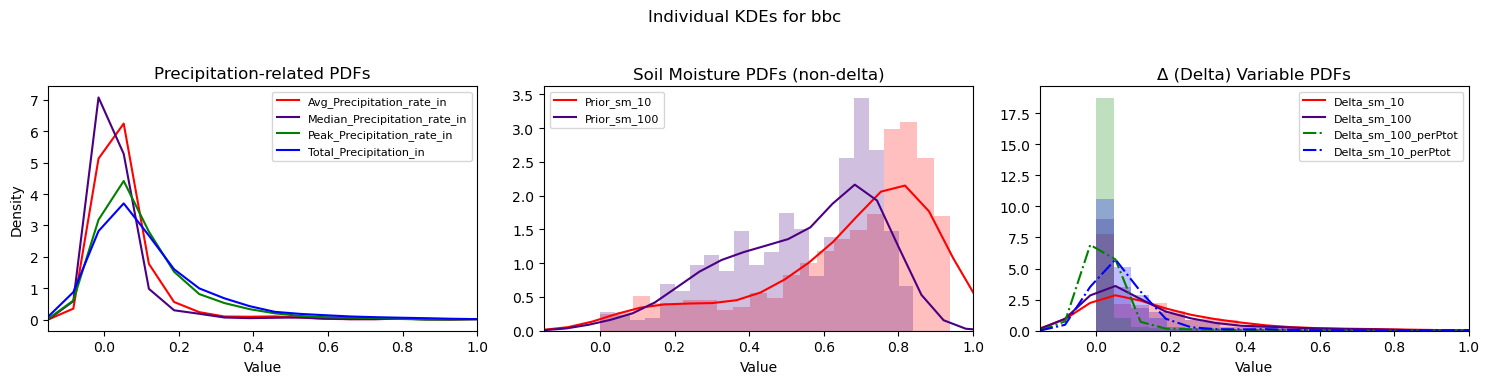

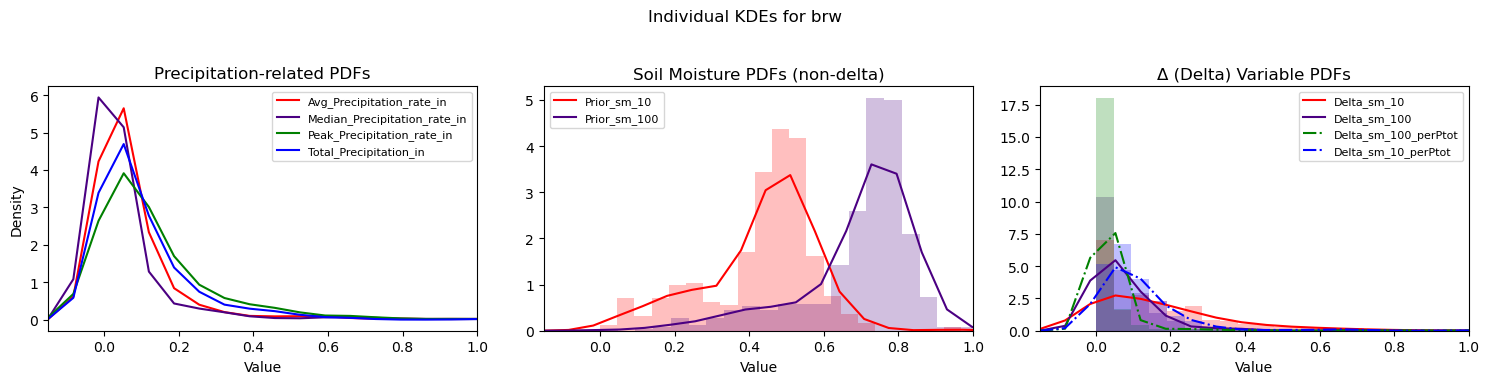

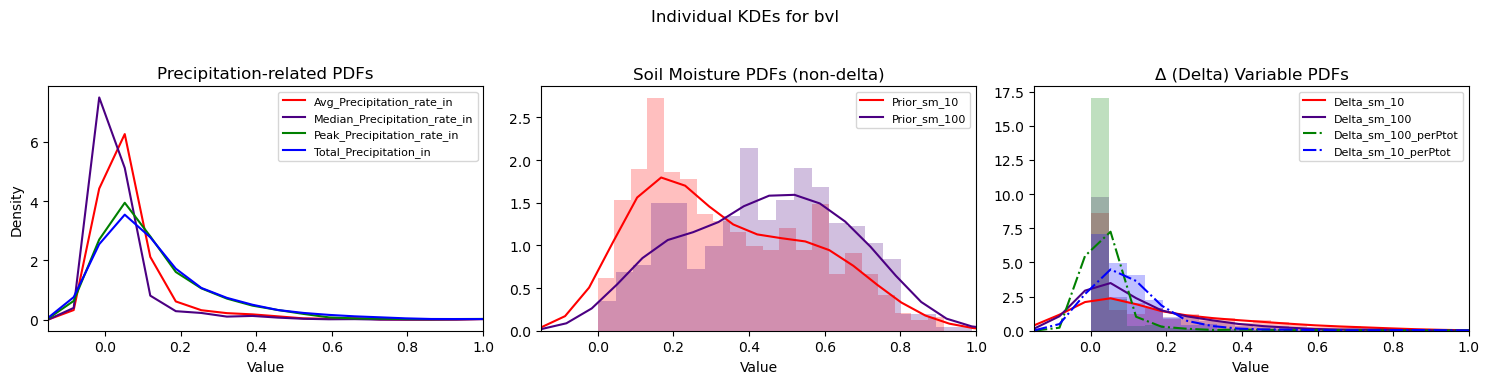

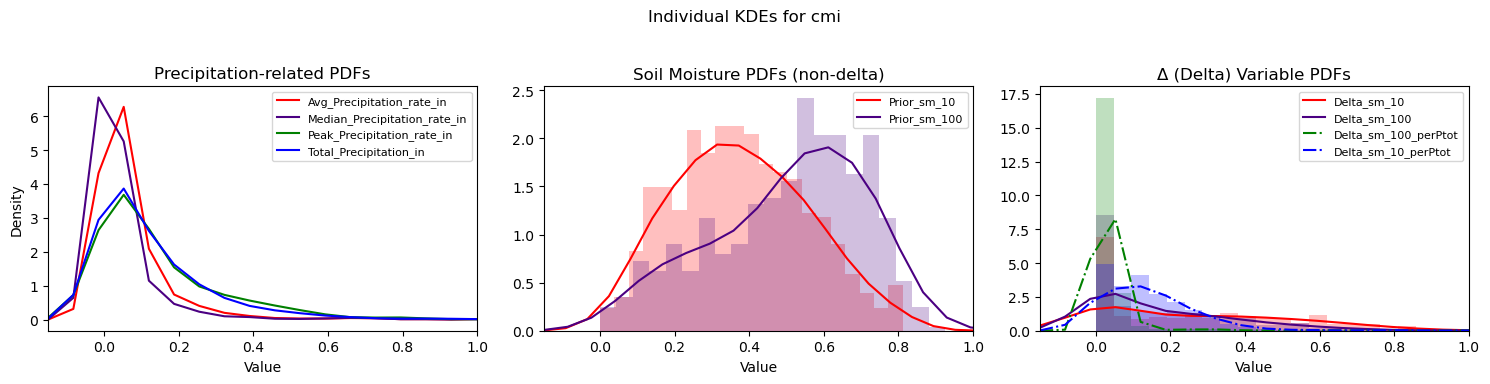

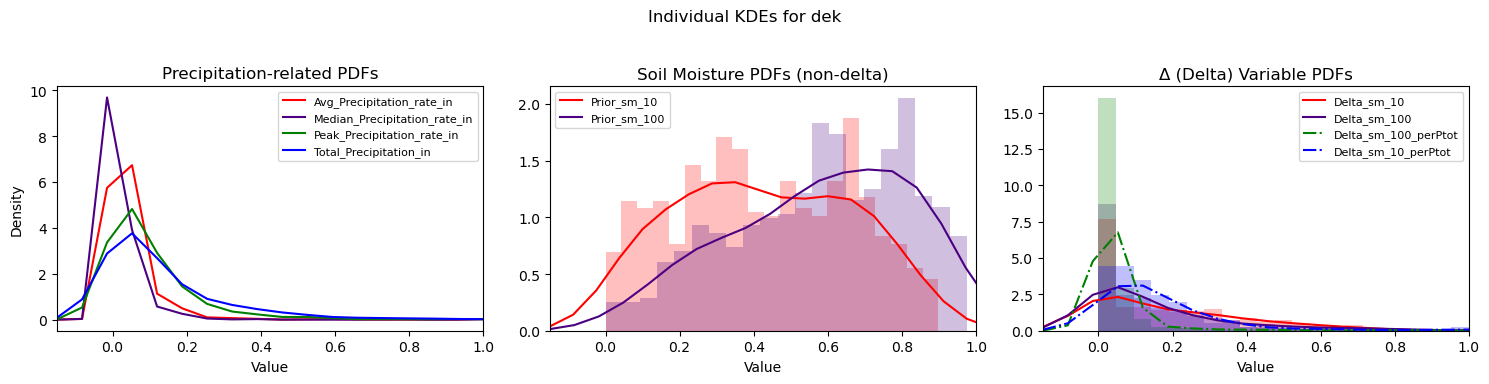

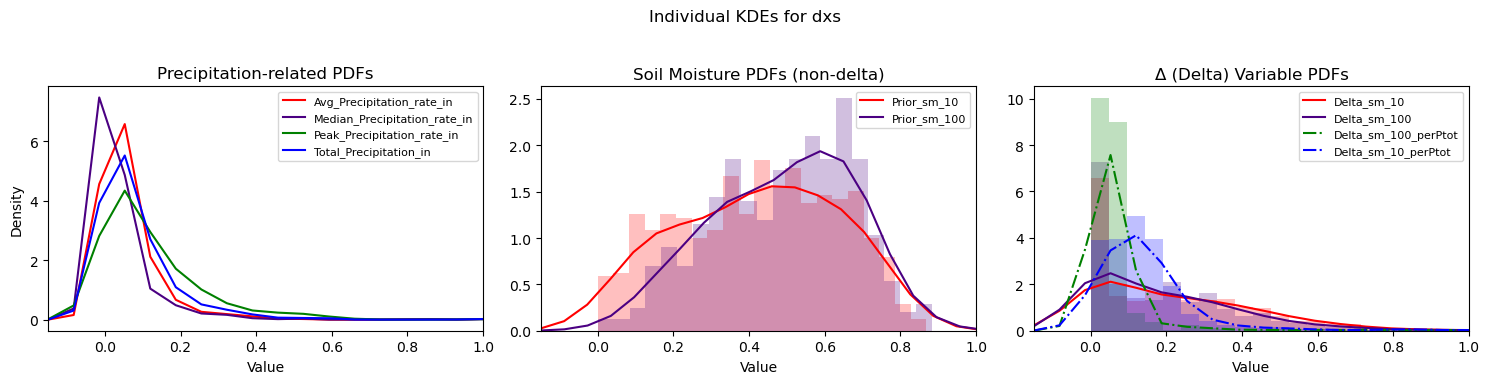

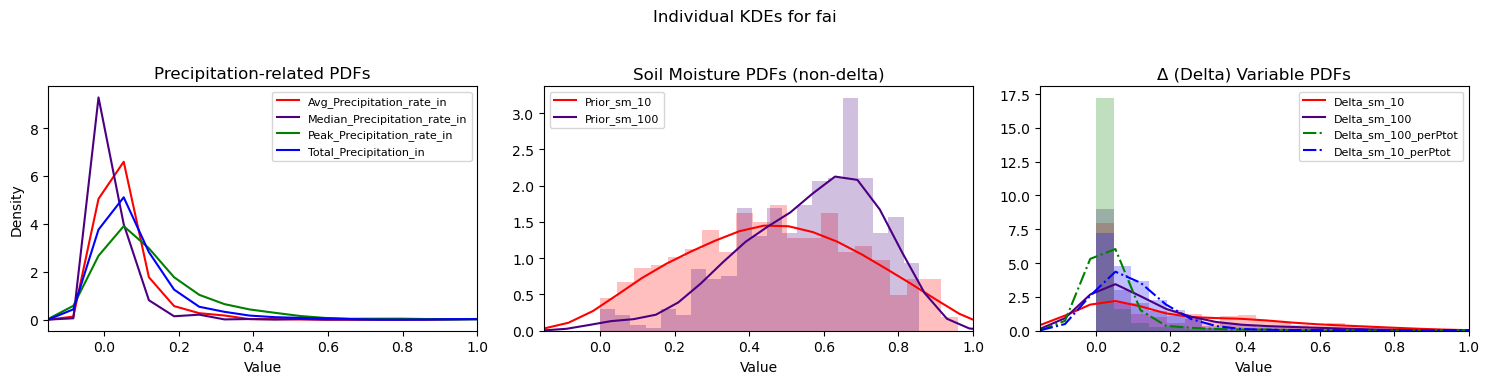

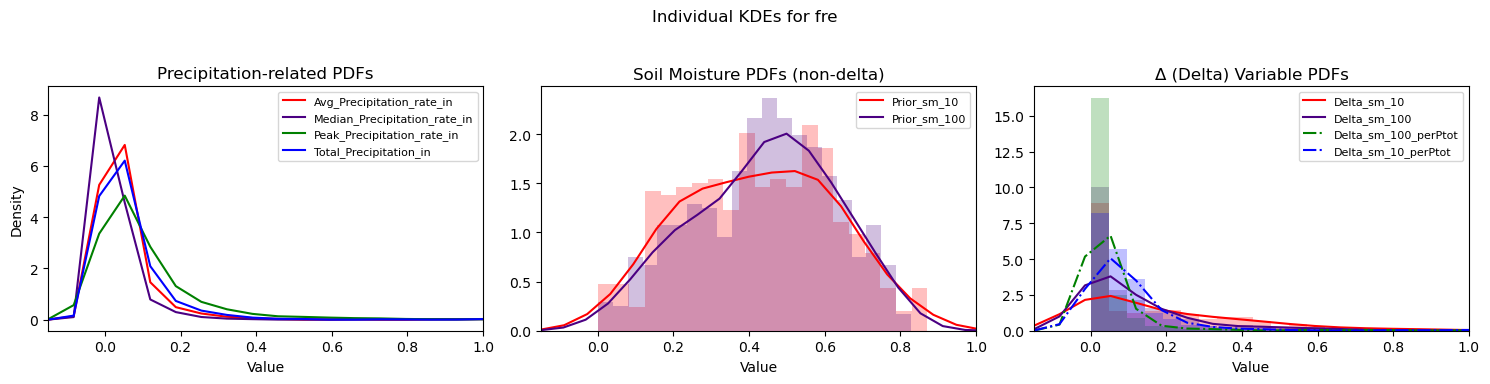

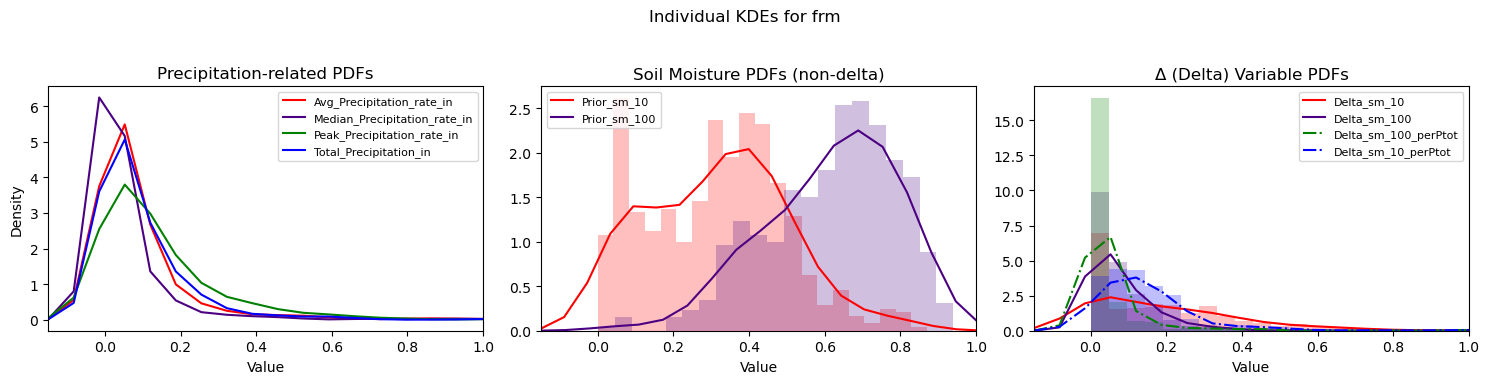

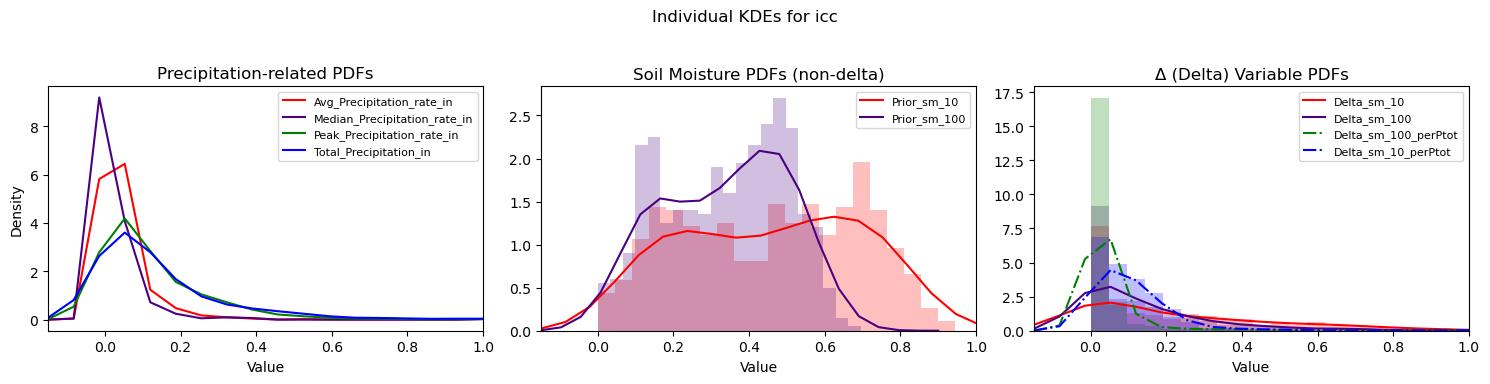

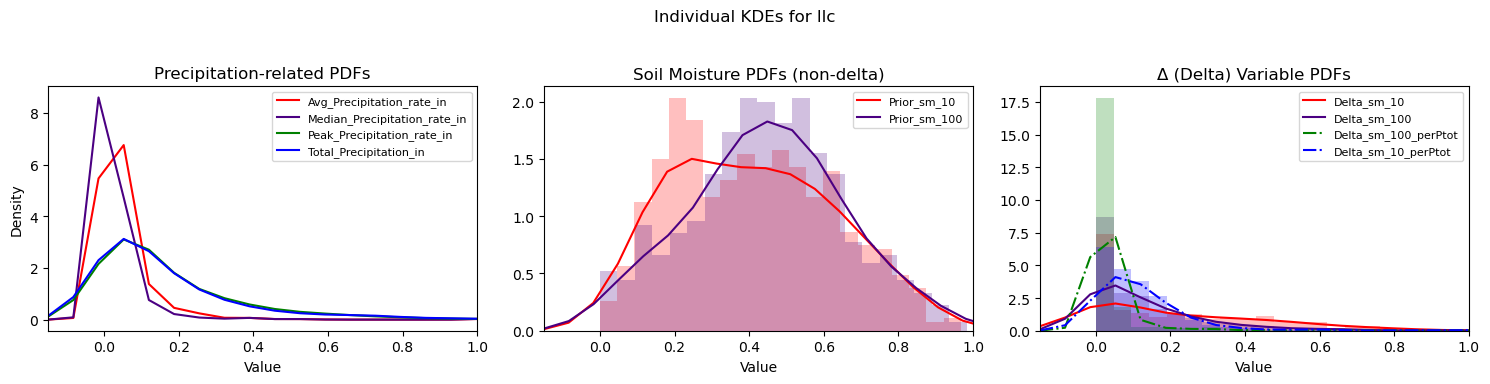

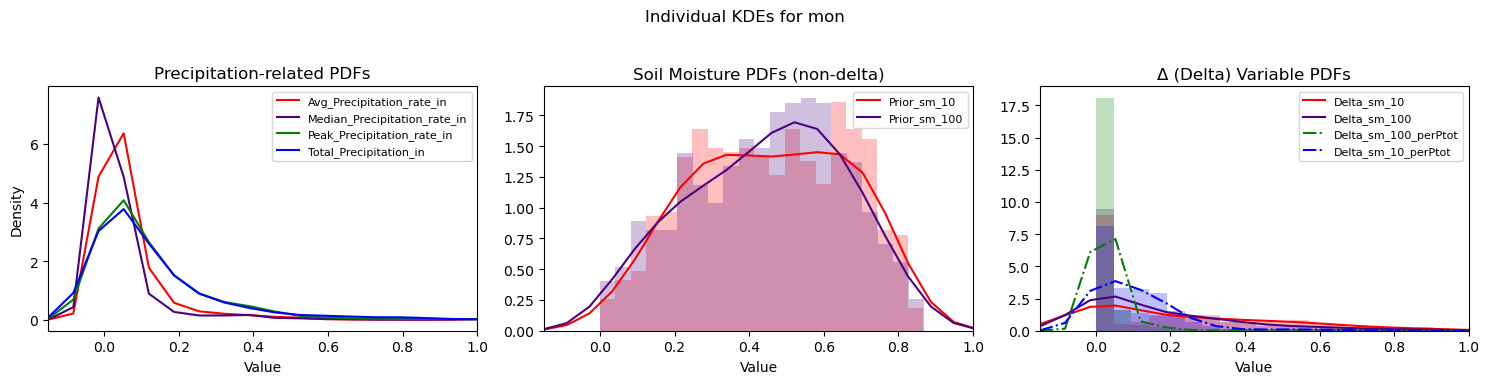

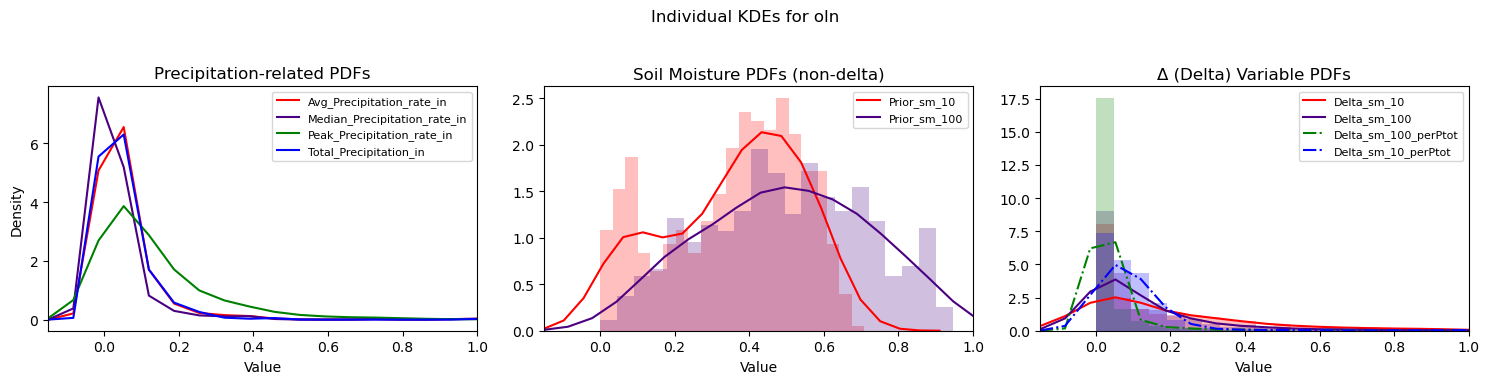

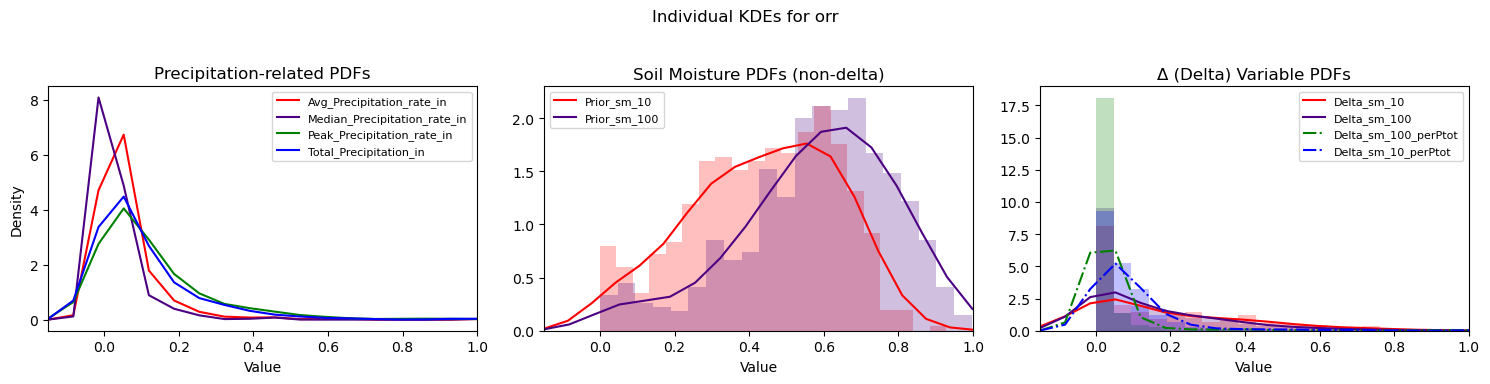

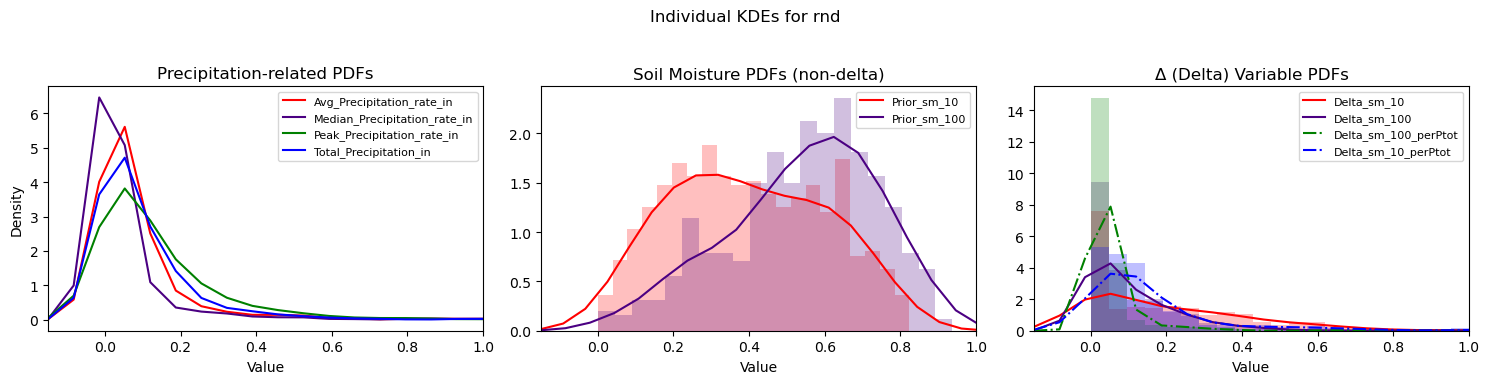

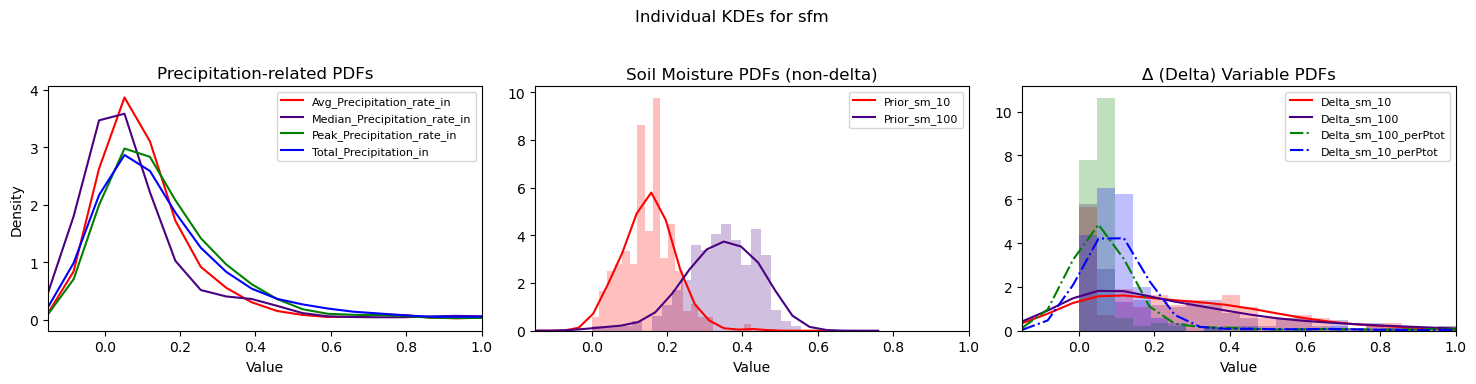

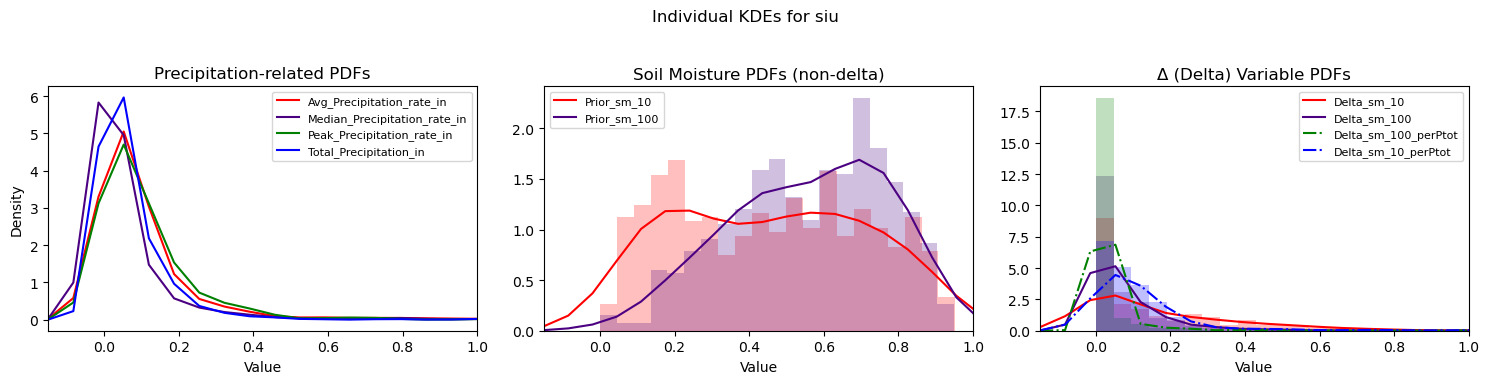

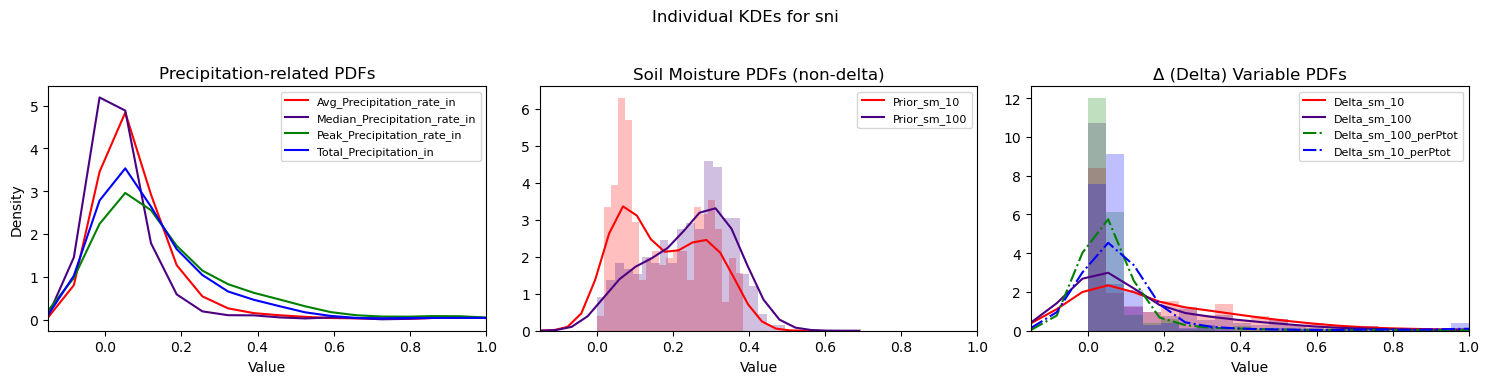

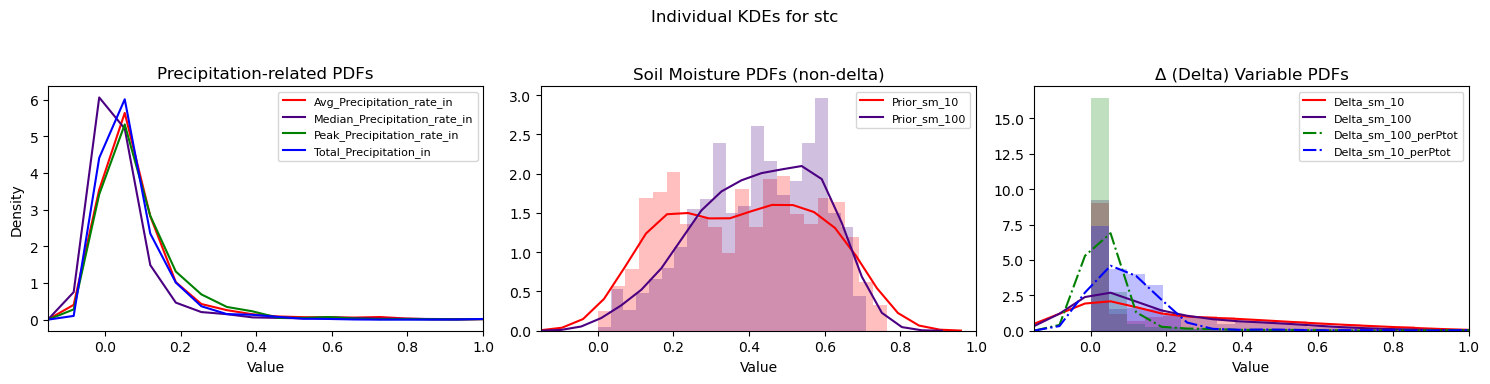

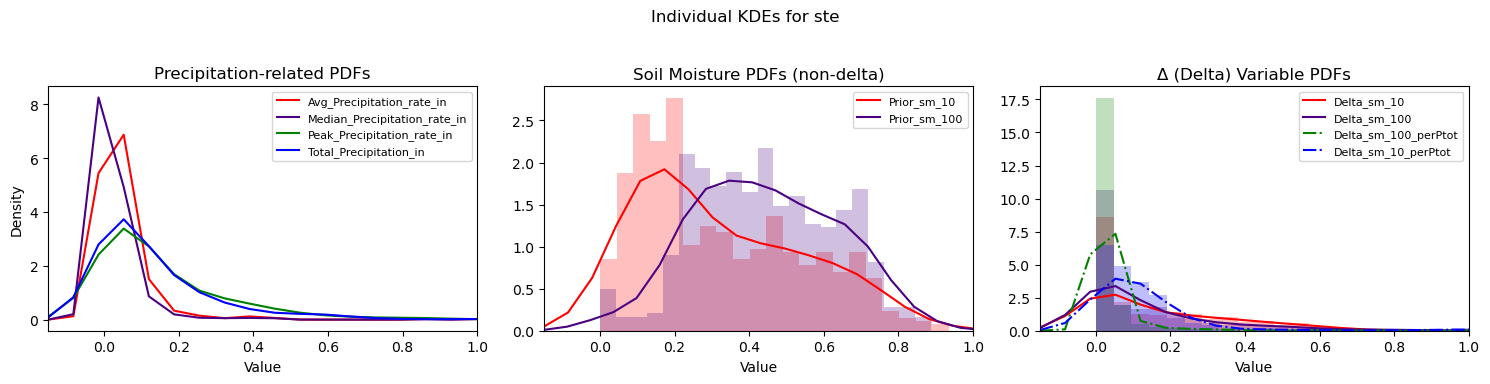

In [24]:
import matplotlib.pyplot as plt
from itertools import cycle

station_labels = list(all_station_ind_data.keys())
color_list = ['red', 'indigo', 'green', 'blue']
n_res = 21

for station_label in station_labels:
    station_data = all_station_ind_data.get(station_label)
    if not station_data:
        print(f'⚠️ No KDE data for station {station_label}; skipping.')
        continue

    raw_data = Apr_2_Oct_Station_events_dict.get(station_label)
    if raw_data is None:
        print(f'⚠️ Missing raw data for station {station_label}; skipping.')
        continue

    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
    fig.suptitle(f'Individual KDEs for {station_label}')
    delta_dashed_vars = {'Delta_sm_100_perPtot', 'Delta_sm_10_perPtot'}

    def plot_category(axis_index, filter_fn, title, xlabel, include_hist=False):
        ax = axes[axis_index]
        color_cycle = cycle(color_list)
        plotted = False

        for var_name, data in sorted(station_data.items()):
            if not filter_fn(var_name):
                continue
            color = next(color_cycle)
            linestyle = '-.' if axis_index == 2 and var_name in delta_dashed_vars else 'solid'
            ax.plot(data['axis'], data['pdf'], color=color, linestyle=linestyle, label=var_name)
            if include_hist:
                try:
                    ax.hist(raw_data[var_name], color=color, density=True, bins=n_res, alpha=0.25)
                except (KeyError, TypeError, AttributeError):
                    print(f'⚠️ Raw data missing for {station_label}::{var_name}; skipping histogram.')
            plotted = True

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_xlim([-0.15, 1.0])
        if axis_index == 0:
            ax.set_ylabel('Density')
        if plotted:
            ax.legend(fontsize=8)
        else:
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center', va='center')

    plot_category(0, lambda name: 'Precipitation' in name, 'Precipitation-related PDFs', 'Value')
    plot_category(1, lambda name: 'sm' in name.lower() and 'delta' not in name.lower(),
                  'Soil Moisture PDFs (non-delta)', 'Value', include_hist=True)
    plot_category(2, lambda name: 'delta' in name.lower(), 'Δ (Delta) Variable PDFs', 'Value', include_hist=True)

    fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# plot the joint KDEs

### total Precip vs Delta SM

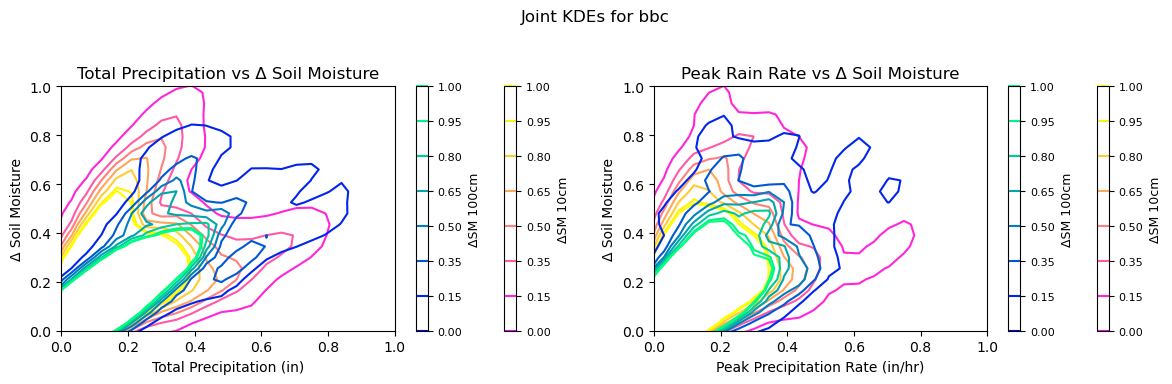

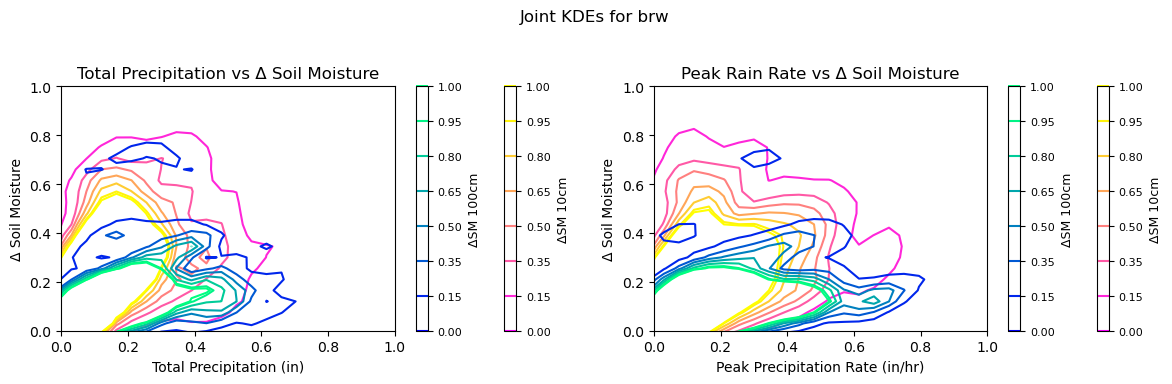

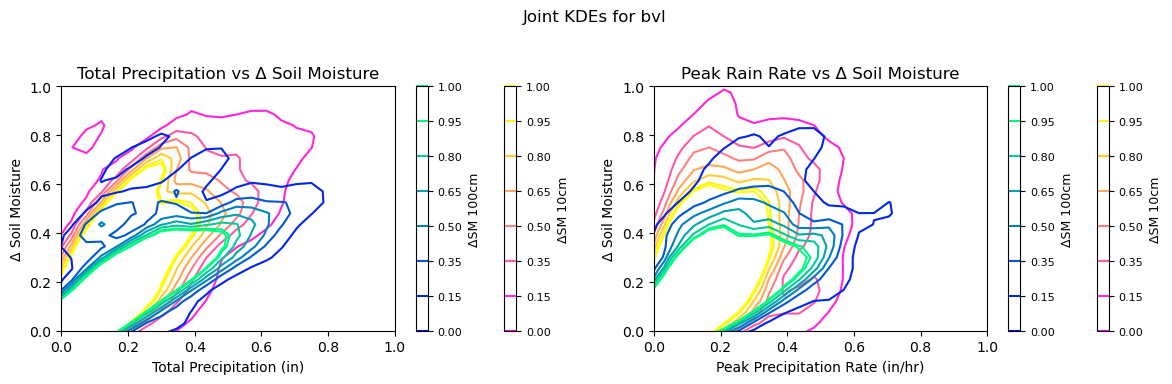

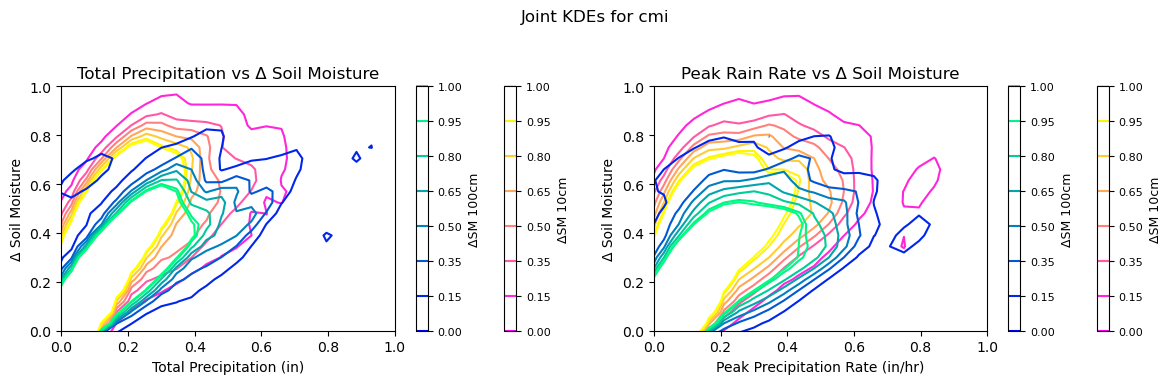

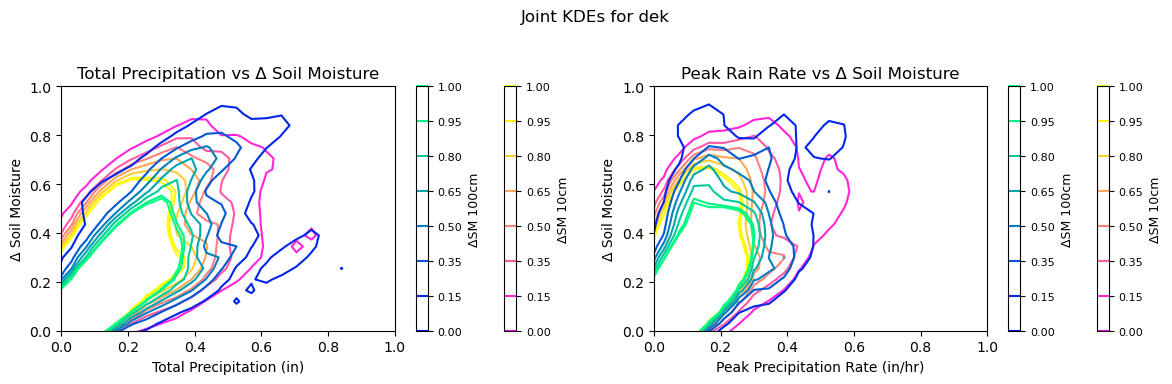

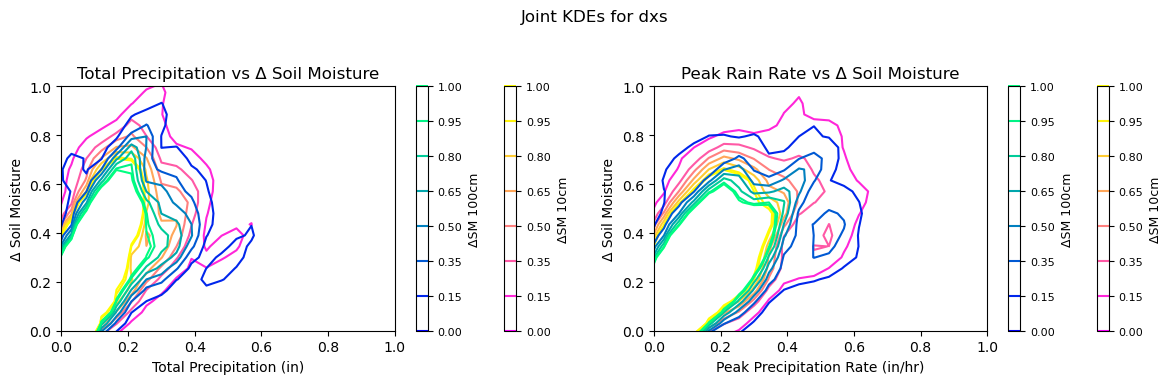

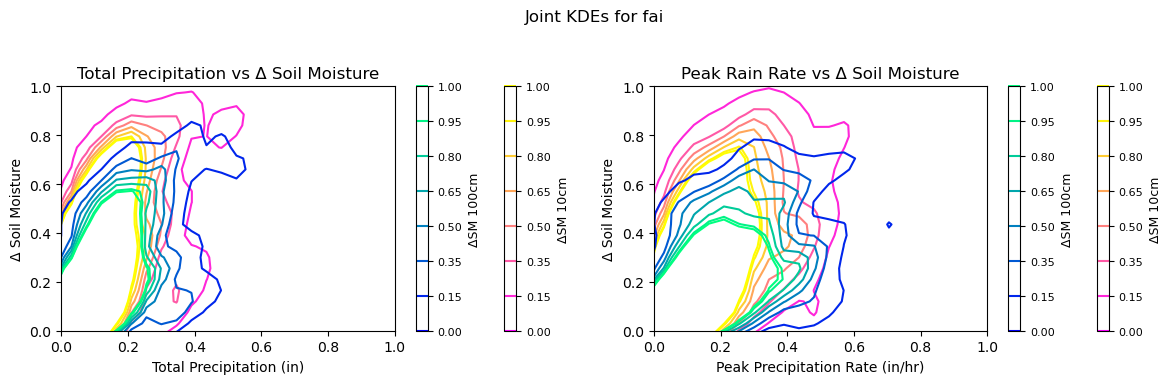

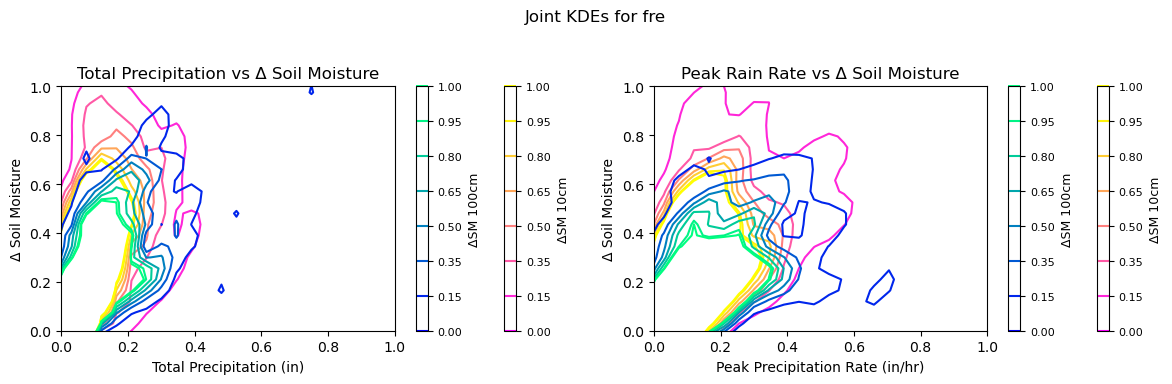

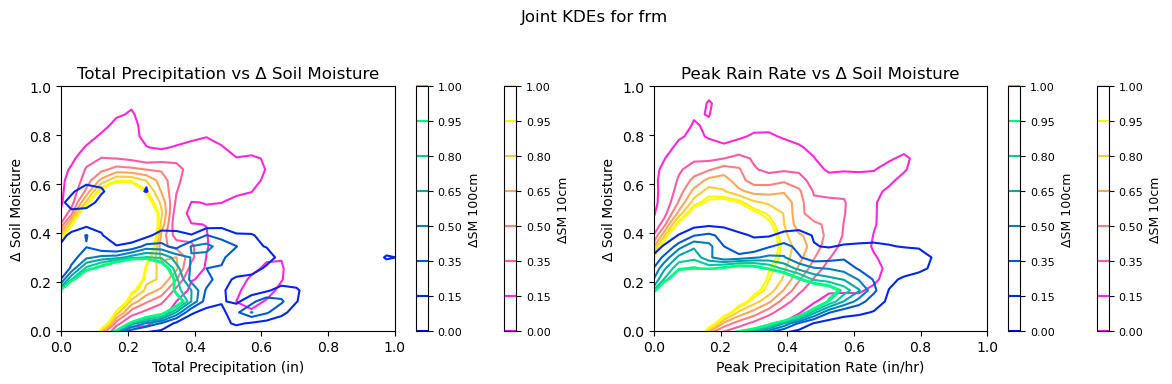

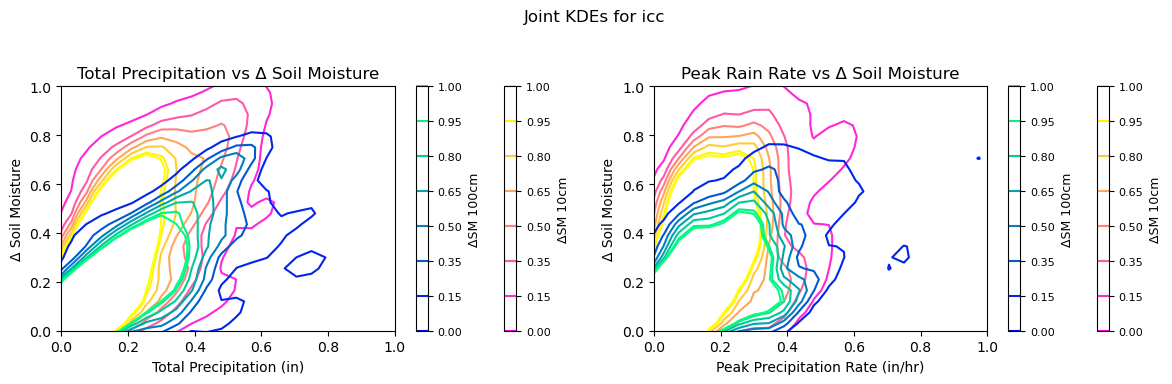

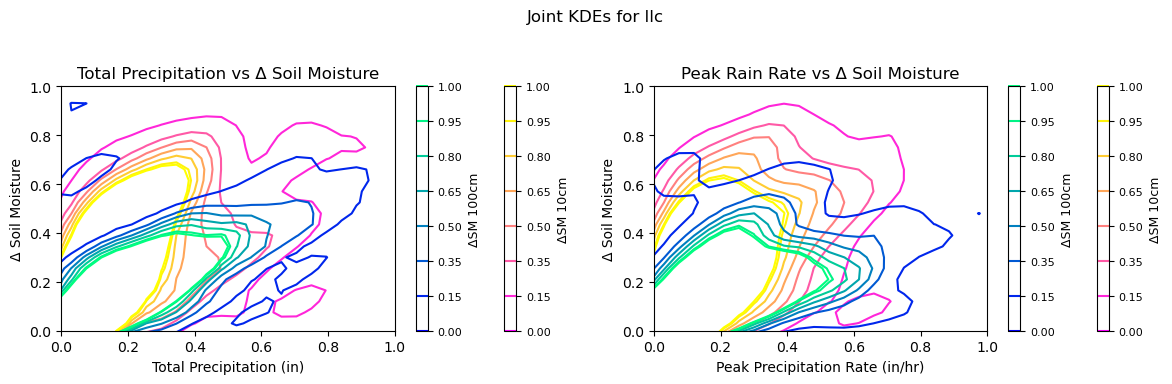

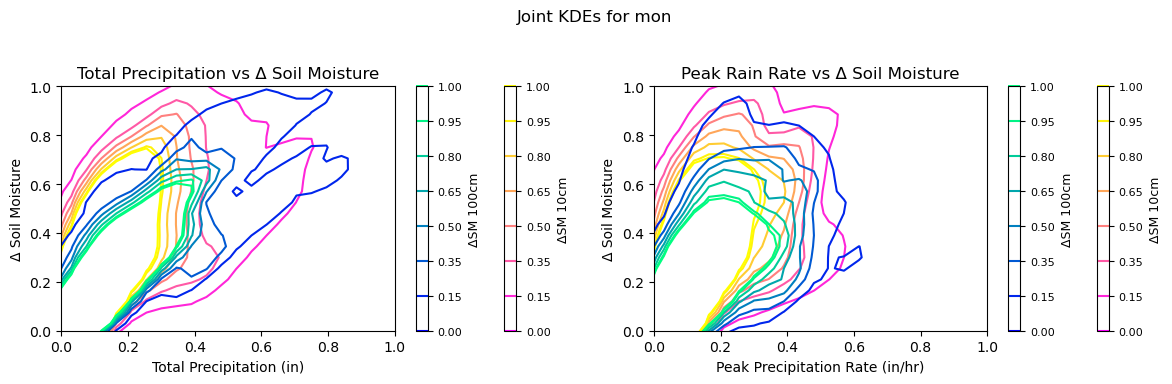

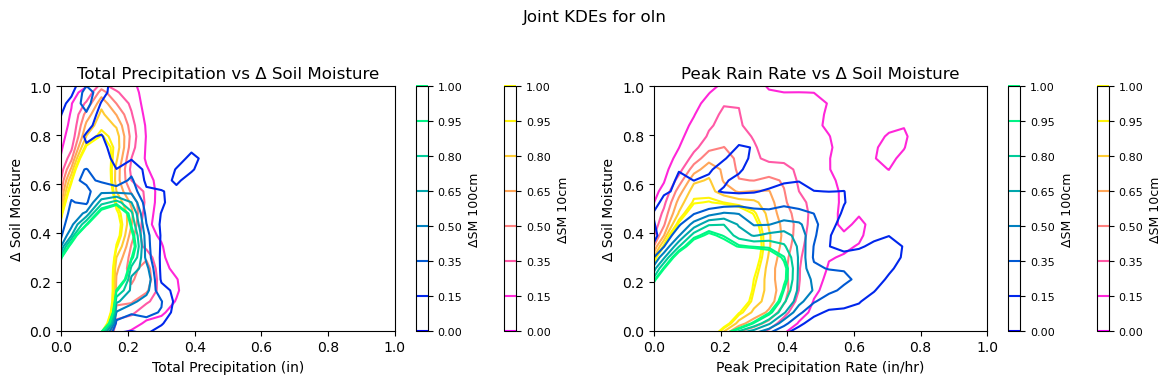

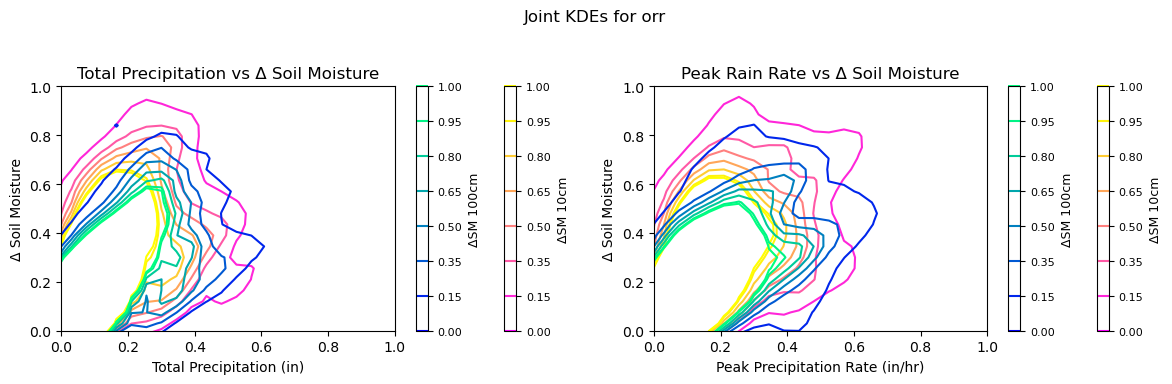

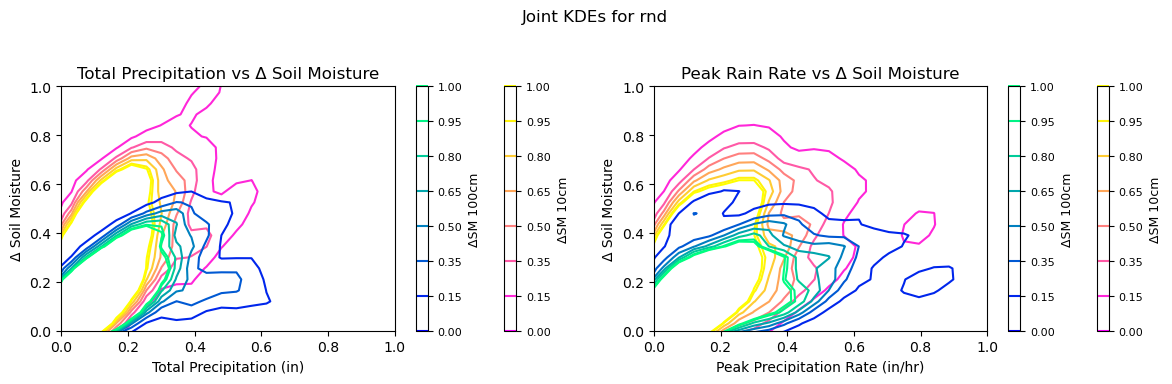

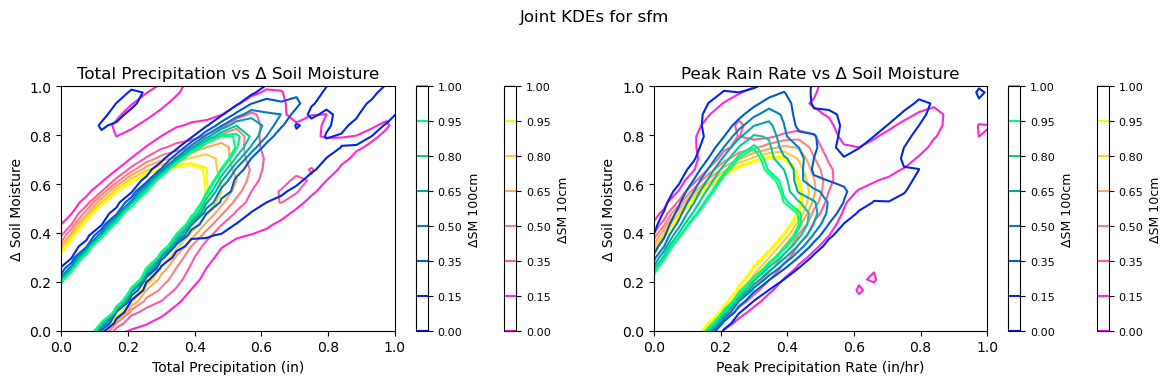

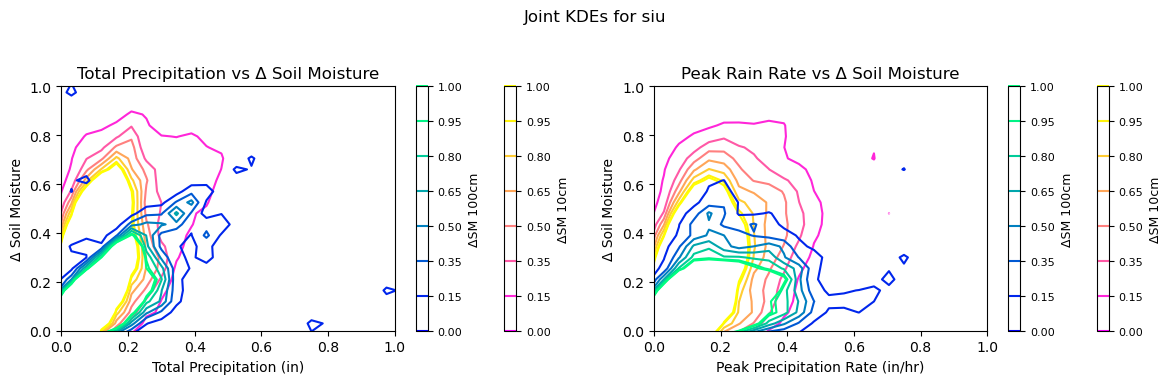

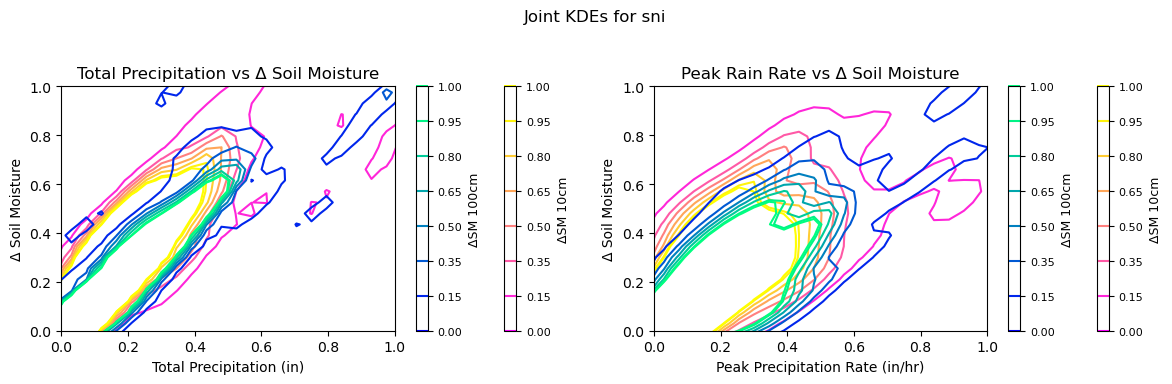

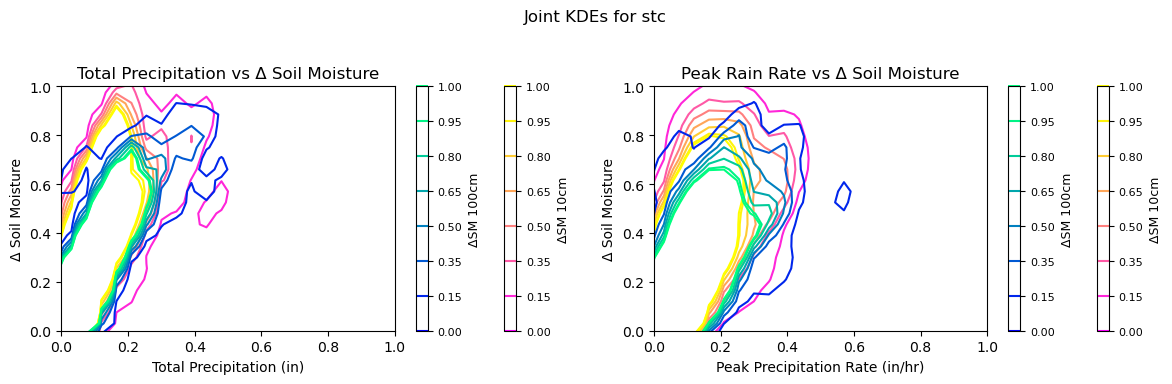

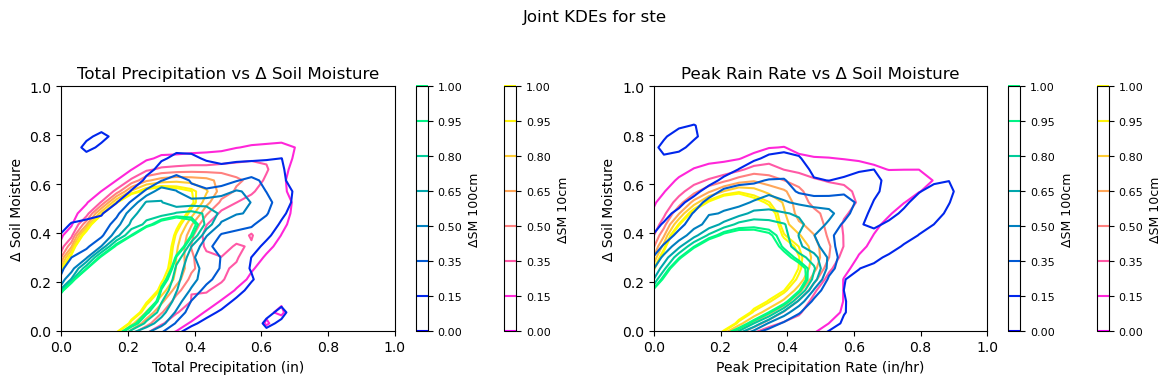

In [18]:
import matplotlib.pyplot as plt
from matplotlib import colormaps
station_labels = list(all_station_ind_data.keys())
contour_levels = [0, 0.15, 0.35, 0.50, 0.65, 0.80, 0.95, 1.0]
delta_configs = [
    ('Delta_sm_10', 'spring', 'ΔSM 10cm'),
    ('Delta_sm_100', 'winter', 'ΔSM 100cm')
]
plot_specs = [
    ('Total_Precipitation_in', 'Total Precipitation vs Δ Soil Moisture', 'Total Precipitation (in)', 'Δ Soil Moisture'),
    ('Peak_Precipitation_rate_in', 'Peak Rain Rate vs Δ Soil Moisture', 'Peak Precipitation Rate (in/hr)', 'Δ Soil Moisture')
]

for station_label in station_labels:
    station_data = all_station_joint_data.get(station_label)
    if not station_data:
        print(f'⚠️ No joint KDE data for station {station_label}; skipping.')
        continue

    fig, axes = plt.subplots(1, len(plot_specs), figsize=(6 * len(plot_specs), 4), sharey=False)
    if len(plot_specs) == 1:
        axes = [axes]

    fig.suptitle(f'Joint KDEs for {station_label}')

    for ax, (precip_var, title, xlabel, ylabel) in zip(axes, plot_specs):
        plotted = False
        for delta_var, cmap_name, legend_label in delta_configs:
            joint_key = f'joint_entropy_{precip_var}_{delta_var}'
            data = station_data.get(joint_key)
            if data is None:
                print(f'⚠️ Missing joint KDE for {station_label}::{joint_key}; skipping.')
                continue

            try:
                cmap = colormaps[cmap_name]
            except KeyError:
                print(f'⚠️ Colormap {cmap_name} unavailable; using viridis instead.')
                cmap = colormaps['viridis']

            grid_x = data.get('x_axis')
            grid_y = data.get('z_axis')
            if grid_x is None or grid_y is None:
                print(f'⚠️ Missing grid axes for {station_label}::{joint_key}; skipping.')
                continue

            X, Y = np.meshgrid(grid_x, grid_y, indexing='ij')

            try:
                contour = ax.contour(X, Y, data['pdf'], levels=contour_levels, cmap=cmap)
            except Exception as exc:
                print(f'⚠️ Failed to contour {station_label}::{joint_key}: {exc}')
                continue

            cbar = fig.colorbar(contour, ax=ax)
            cbar.set_label(legend_label, fontsize=9)
            cbar.ax.tick_params(labelsize=8)
            plotted = True

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_ylim([0,1.0])
        ax.set_xlim([0,1.0])

        if not plotted:
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center', va='center')

    fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


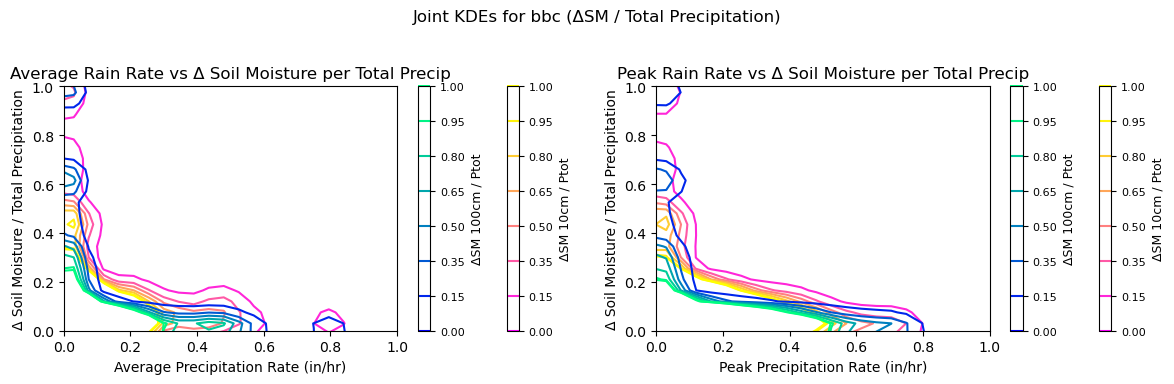

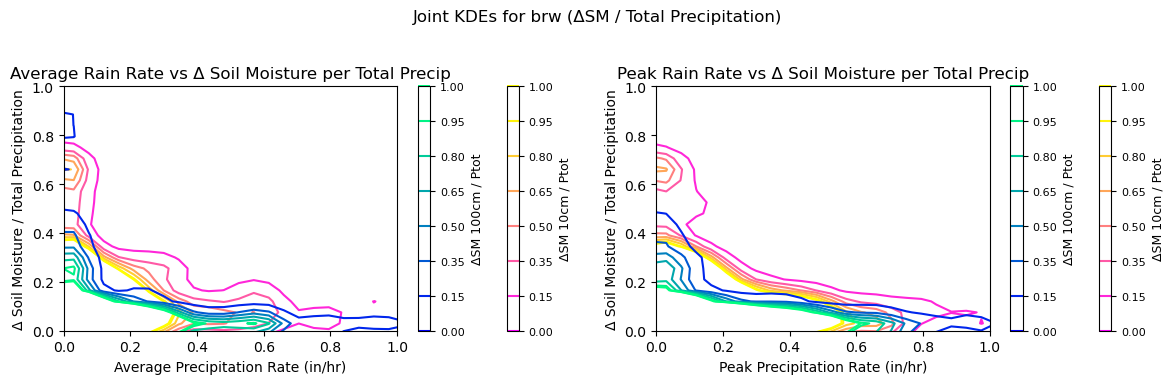

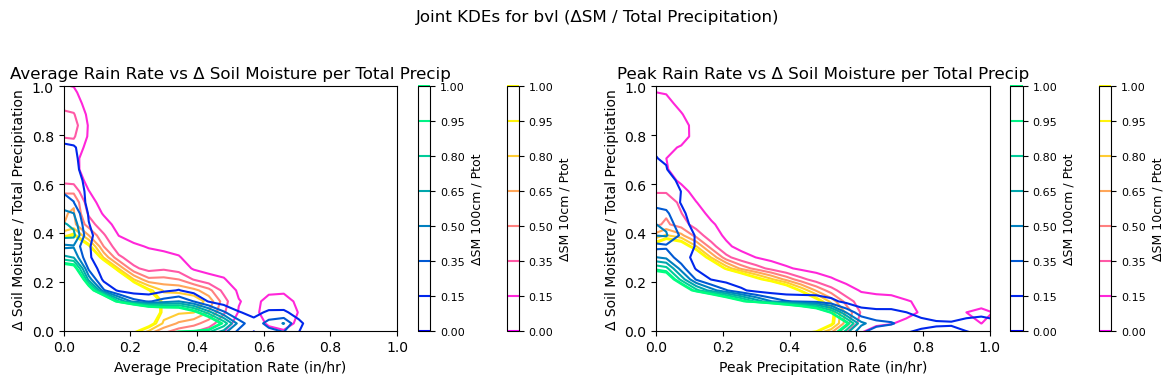

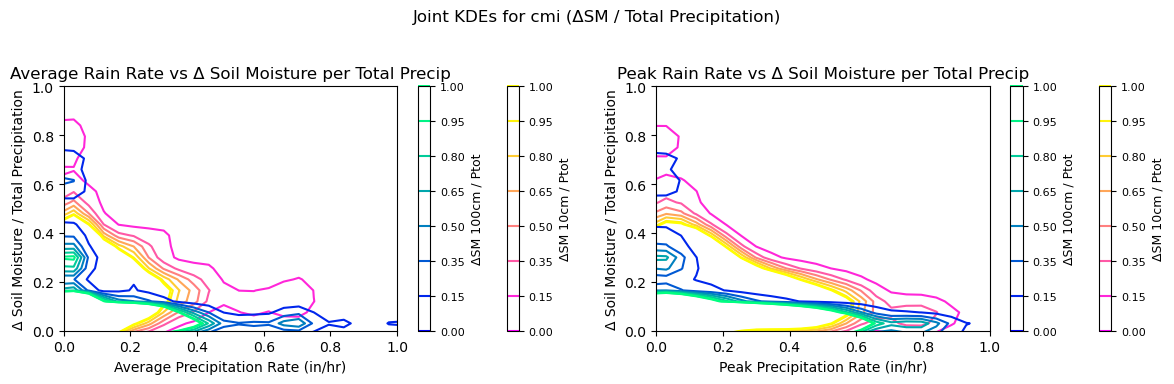

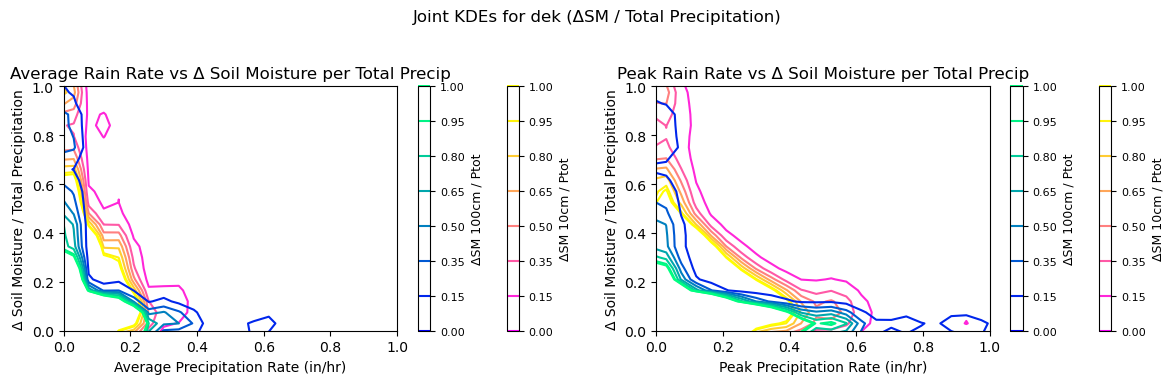

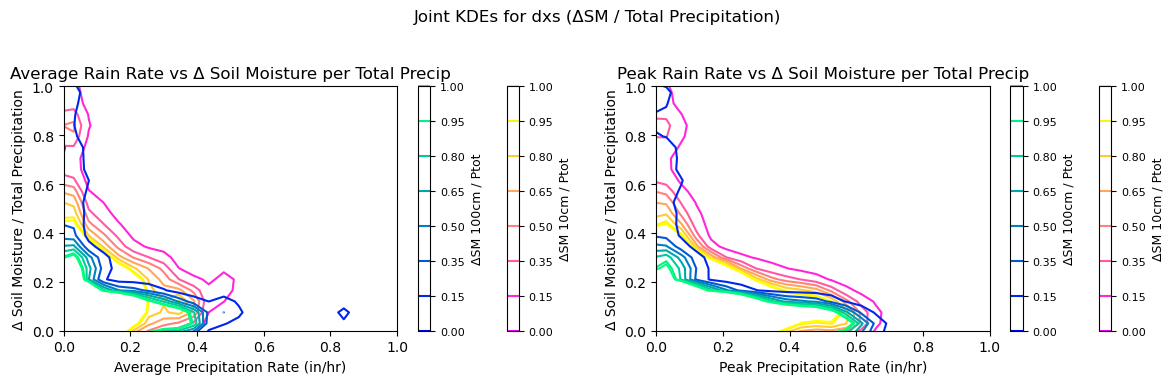

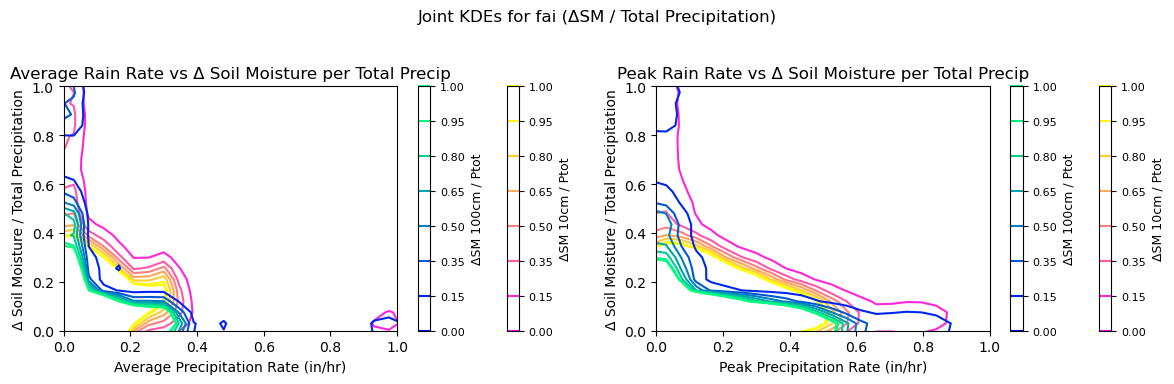

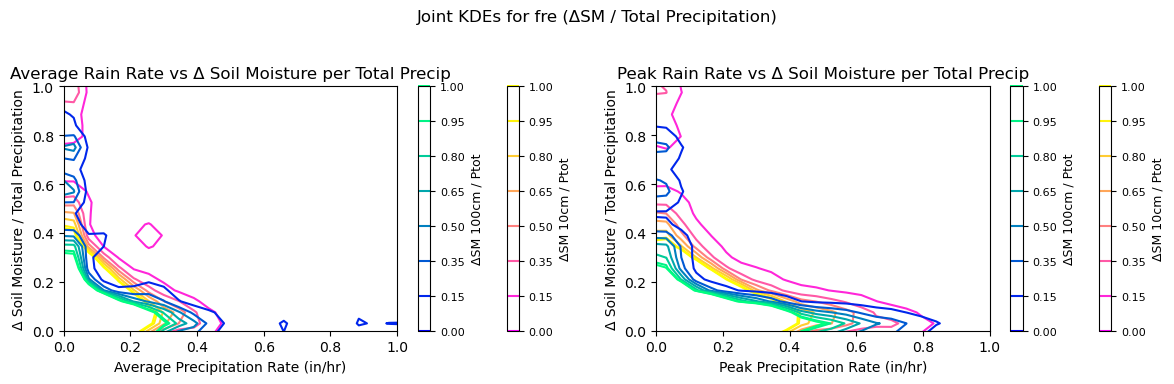

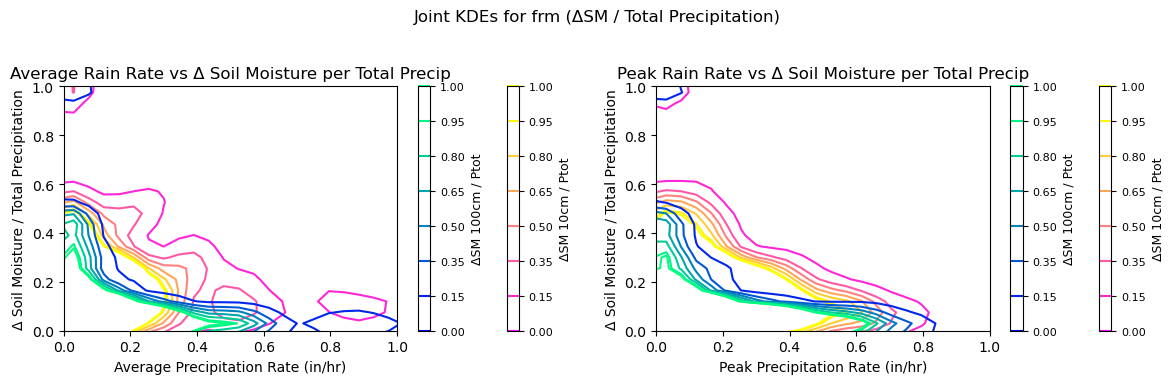

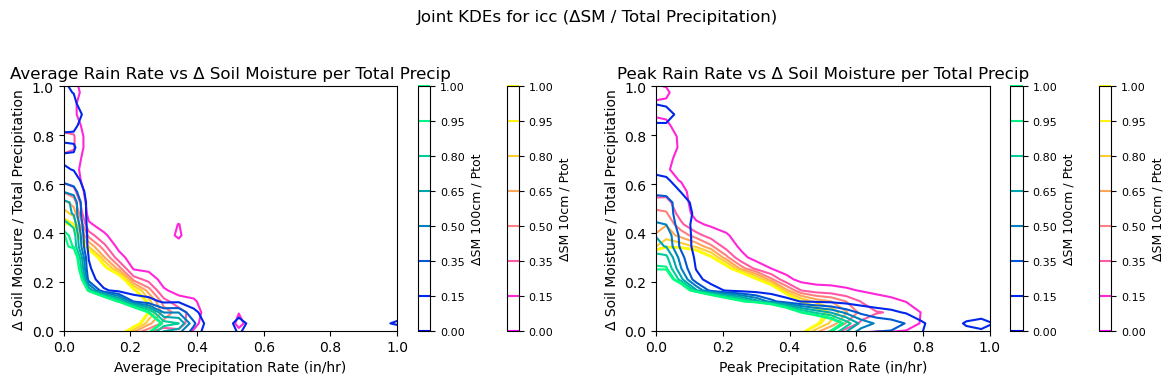

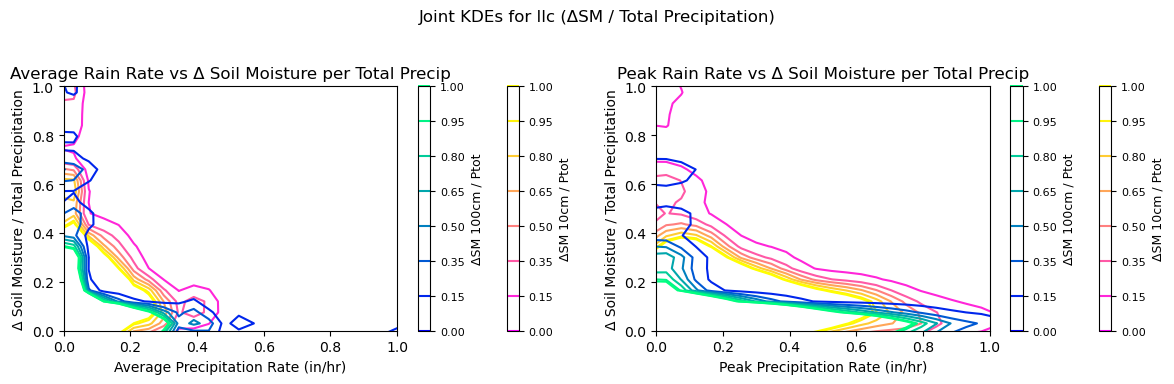

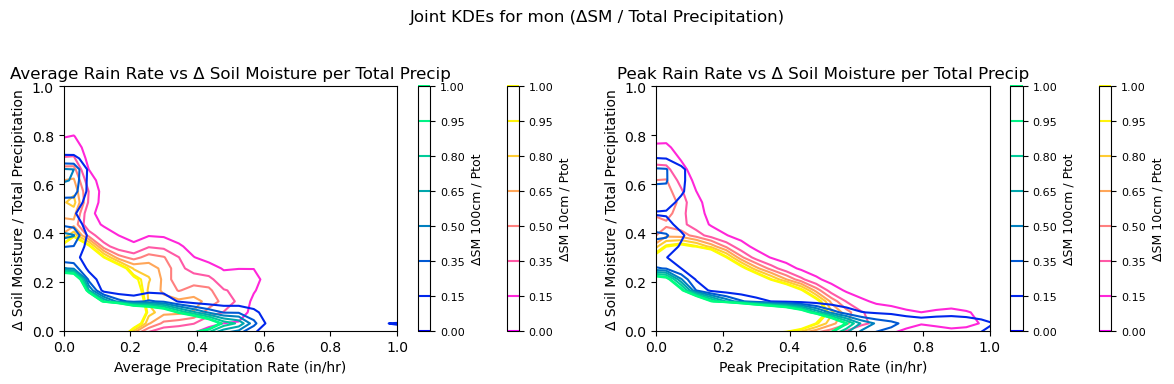

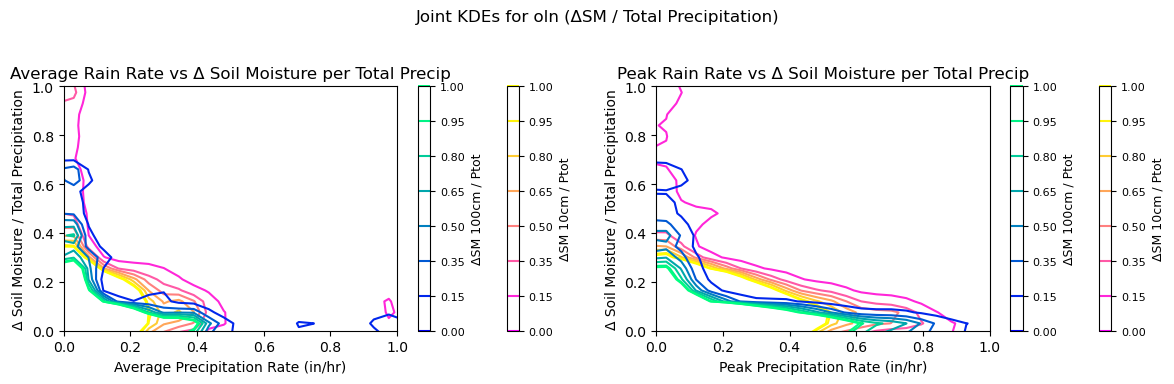

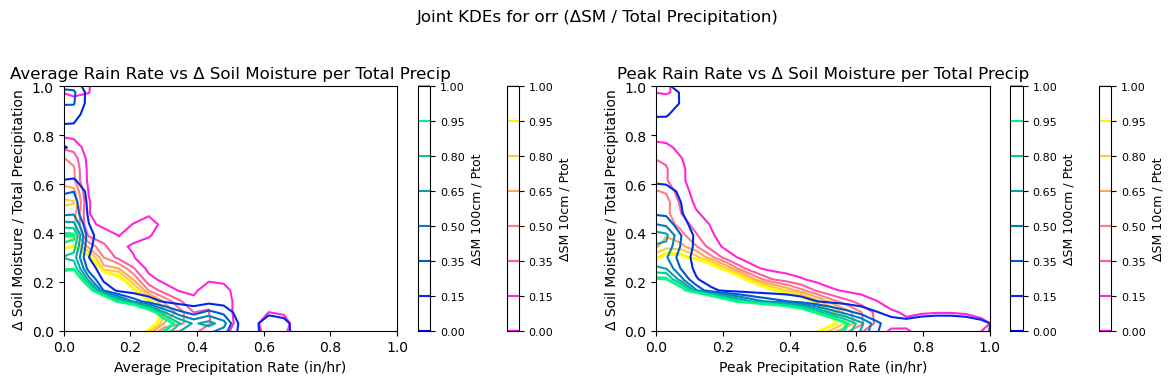

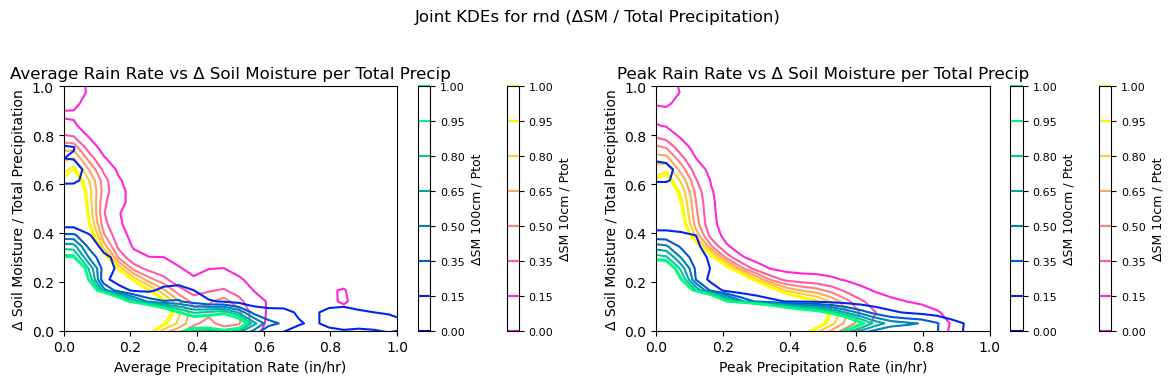

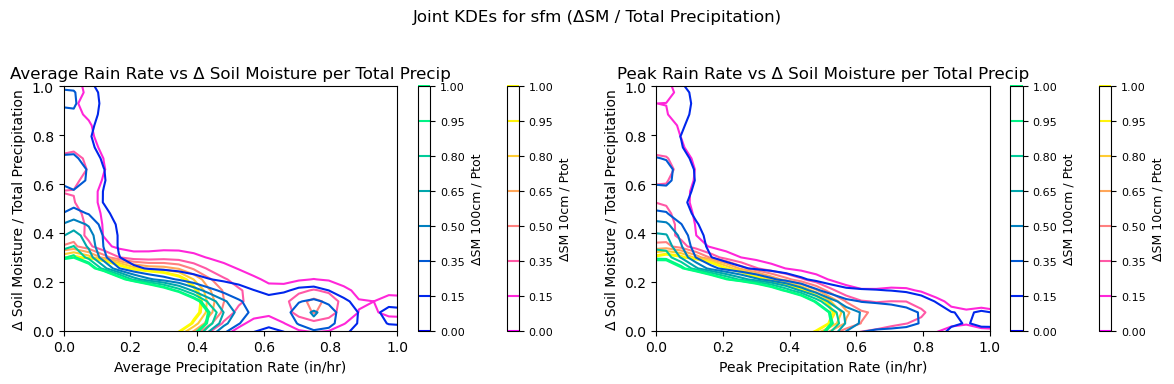

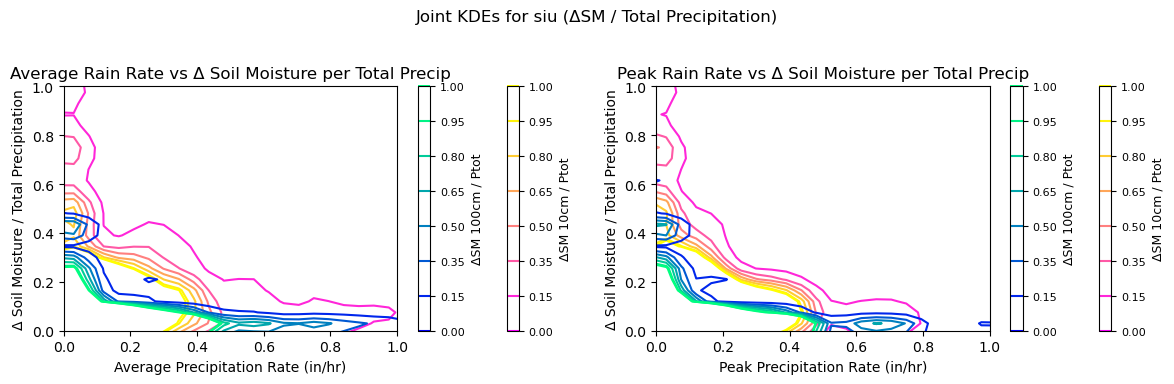

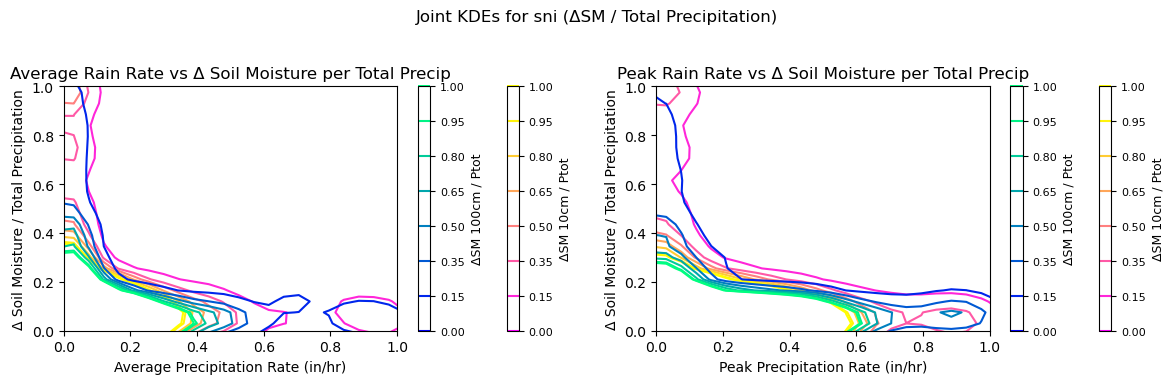

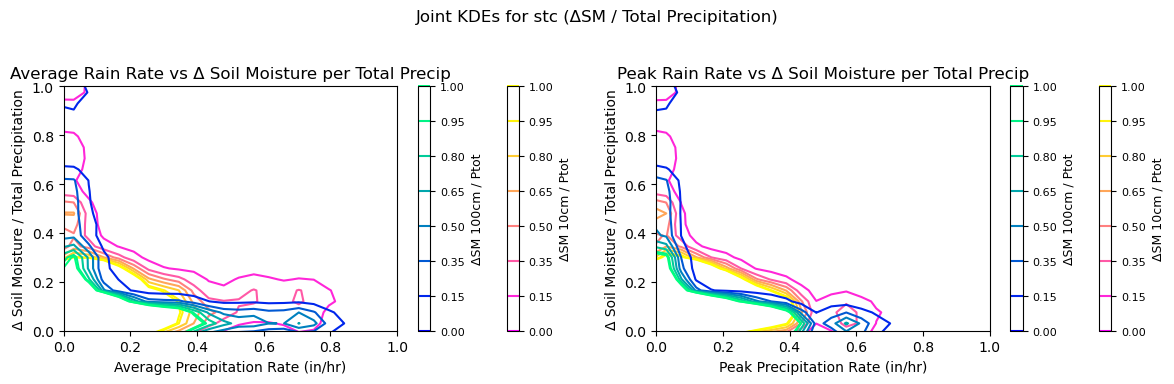

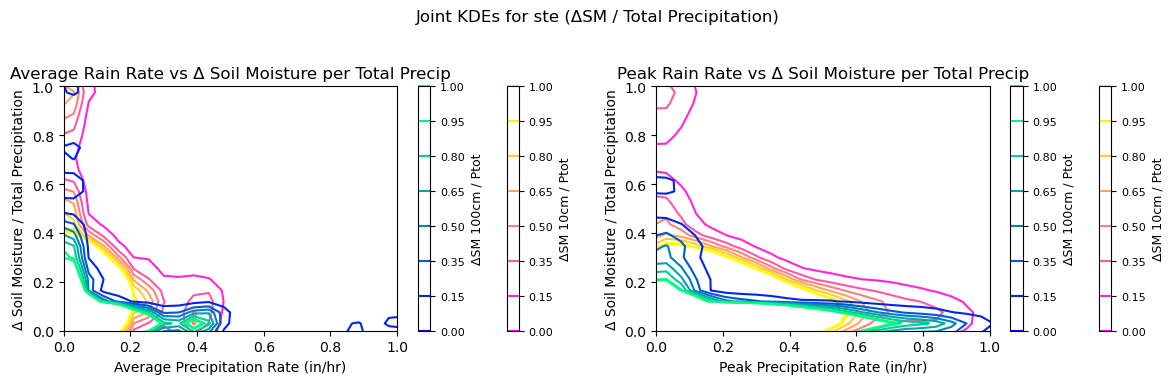

In [26]:
import matplotlib.pyplot as plt
from matplotlib import colormaps
station_labels = list(all_station_ind_data.keys())
contour_levels = [0, 0.15, 0.35, 0.50, 0.65, 0.80, 0.95, 1.0]
delta_configs = [
    ('Delta_sm_10_perPtot', 'spring', 'ΔSM 10cm / Ptot'),
    ('Delta_sm_100_perPtot', 'winter', 'ΔSM 100cm / Ptot')
]
plot_specs = [
    ('Avg_Precipitation_rate_in', 'Average Rain Rate vs Δ Soil Moisture per Total Precip', 'Average Precipitation Rate (in/hr)', 'Δ Soil Moisture / Total Precipitation'),
    ('Peak_Precipitation_rate_in', 'Peak Rain Rate vs Δ Soil Moisture per Total Precip', 'Peak Precipitation Rate (in/hr)', 'Δ Soil Moisture / Total Precipitation')
]

for station_label in station_labels:
    station_data = all_station_joint_data.get(station_label)
    if not station_data:
        print(f'⚠️ No joint KDE data for station {station_label}; skipping.')
        continue

    fig, axes = plt.subplots(1, len(plot_specs), figsize=(6 * len(plot_specs), 4), sharey=False)
    if len(plot_specs) == 1:
        axes = [axes]

    fig.suptitle(f'Joint KDEs for {station_label} (ΔSM / Total Precipitation)')

    for ax, (precip_var, title, xlabel, ylabel) in zip(axes, plot_specs):
        plotted = False
        x_range = None
        y_range = None
        for delta_var, cmap_name, legend_label in delta_configs:
            joint_key = f'joint_entropy_{precip_var}_{delta_var}'
            data = station_data.get(joint_key)
            if data is None:
                print(f'⚠️ Missing joint KDE for {station_label}::{joint_key}; skipping.')
                continue

            try:
                cmap = colormaps[cmap_name]
            except KeyError:
                print(f'⚠️ Colormap {cmap_name} unavailable; using viridis instead.')
                cmap = colormaps['viridis']

            grid_x = data.get('x_axis')
            grid_y = data.get('z_axis')
            if grid_x is None or grid_y is None:
                print(f'⚠️ Missing grid axes for {station_label}::{joint_key}; skipping.')
                continue

            X, Y = np.meshgrid(grid_x, grid_y, indexing='ij')

            try:
                contour = ax.contour(X, Y, data['pdf'], levels=contour_levels, cmap=cmap)
            except Exception as exc:
                print(f'⚠️ Failed to contour {station_label}::{joint_key}: {exc}')
                continue

            cbar = fig.colorbar(contour, ax=ax)
            cbar.set_label(legend_label, fontsize=9)
            cbar.ax.tick_params(labelsize=8)
            plotted = True

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_ylim([0,1.0])
        ax.set_xlim([0,1.0])

        if x_range:
            ax.set_xlim(x_range)
        if y_range:
            ax.set_ylim(y_range)

        if not plotted:
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center', va='center')

    fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


### joint deltaSM/ptot vs peak precip